# <div align="center">Phân tích và dự đoán GDP một số nước châu Á tiêu biểu</div>

Trong báo cáo này, ta sẽ nghiên cứu GDP một số nước châu Á trong năm 2000 - 2024, đồng thời phân tích một số nhân tố kinh tế, từ đó xác định **nhân tố ảnh hưởng mạnh nhất đến GDP**, qua đó **dự đoán GDP của các nước này đến năm 2030**.

### 1. Xử lý dữ liệu GDP:
Đầu tiên, ta sẽ kiểm tra và xử lý dữ liệu GDP các nước mà mình đã thu thập được từ bộ chỉ số *World Development Indicators* (WDI) do Ngân hàng Thế Giới (World Bank) tổng hợp ([link dataset](MyData_GDP.csv)). Trước tiên, ta nhập các thư viện và đọc dữ liệu như sau.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats
import statsmodels.api as sm

In [9]:
df = pd.read_csv("Not_GDP_Data.csv",encoding = 'latin-1',decimal = ',')
df


,Country Name,Country Code,Series Name,Series Code,1975 [YR1975],1976 [YR1976],1977 [YR1977],1978 [YR1978],1979 [YR1979],1980 [YR1980],...,2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024]
0,Cambodia,KHM,GDP (current US$),NY.GDP.MKTP.CD,749129748.2,790357254.5,716261764.5,766642356.1,723738502.7,744384129.7,...,24174170369,26556545153,29355665910,33145892169,36685356408,34818073901,36790163687,39994532960,42335646896,46352647037
1,Cambodia,KHM,GDP per capita (current US$),NY.GDP.PCAP.CD,113.8257892,128.8277773,126.3571175,147.1015734,142.2216171,143.154318,...,1547.320104,1675.195557,1826.353917,2036.673776,2225.877055,2081.739142,2167.403242,2325.0305,2429.748535,2627.879698
2,Cambodia,KHM,GDP per person employed (constant 2021 PPP $),SL.GDP.PCAP.EM.KD,..,..,..,..,..,..,...,9205.665981,9550.710214,10144.05318,10801.36654,11405.90729,10831.4793,11356.78018,11632.43825,12003.74992,12516.54613
3,Cambodia,KHM,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,..,..,..,..,..,..,...,20.14084886,18.90798156,17.86817716,16.49794791,15.43850652,17.03965229,16.90441437,16.54408599,17.07844725,16.57687261
4,Cambodia,KHM,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..,..,..,..,..,..,...,55.98122031,56.43183772,56.30005367,55.47139736,55.44686797,59.92179794,72.36103464,72.20706068,66.89266606,71.36358417
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,India,IND,Broad money growth (annual %),FM.LBL.BMNY.ZG,14.05195765,24.48557083,19.16387544,21.15282402,17.71100519,15.89767393,...,10.61772456,6.800954124,10.43104371,10.51961998,10.51024843,12.4791379,11.29710567,..,..,..
204,India,IND,Real interest rate (%),FR.INR.RINR,..,..,..,10.77463133,-1.061145746,4.476508261,...,7.556488414,6.232711415,5.327608862,5.36166639,6.894875427,4.135999578,0.316945144,2.521315449,..,..
205,India,IND,General government final consumption expenditu...,NE.CON.GOVT.ZS,9.487656216,9.779753316,9.209771941,9.439608621,9.894732025,9.651880609,...,10.42829071,10.30854807,10.76719895,10.82321853,11.00267551,11.61245241,10.47637824,10.25503791,10.30542224,9.988824192
206,India,IND,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,..,..,..,..,..,..,...,7.631,7.601,7.618,7.652,6.51,7.859,6.38,4.822,4.172,4.202


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 54 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Country Name   208 non-null    object
 1   Country Code   208 non-null    object
 2   Series Name    208 non-null    object
 3   Series Code    208 non-null    object
 4   1975 [YR1975]  208 non-null    object
 5   1976 [YR1976]  208 non-null    object
 6   1977 [YR1977]  208 non-null    object
 7   1978 [YR1978]  208 non-null    object
 8   1979 [YR1979]  208 non-null    object
 9   1980 [YR1980]  208 non-null    object
 10  1981 [YR1981]  208 non-null    object
 11  1982 [YR1982]  208 non-null    object
 12  1983 [YR1983]  208 non-null    object
 13  1984 [YR1984]  208 non-null    object
 14  1985 [YR1985]  208 non-null    object
 15  1986 [YR1986]  208 non-null    object
 16  1987 [YR1987]  208 non-null    object
 17  1988 [YR1988]  208 non-null    object
 18  1989 [YR1989]  208 non-null   

Ta có thể thay đổi tên các cột năm như sau:

In [59]:
columnsName = ['Country Name','Country Code','Series Name','Series Code']
for i in range(1975,2025):
    columnsName += [i]
df.columns = columnsName
df.head()

,Country Name,Country Code,Series Name,Series Code,1975,1976,1977,1978,1979,1980,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Cambodia,KHM,GDP (current US$),NY.GDP.MKTP.CD,749129748.2,790357254.5,716261764.5,766642356.1,723738502.7,744384129.7,...,24174170369,26556545153,29355665910,33145892169,36685356408,34818073901,36790163687,39994532960,42335646896,46352647037
1,Cambodia,KHM,GDP per capita (current US$),NY.GDP.PCAP.CD,113.8257892,128.8277773,126.3571175,147.1015734,142.2216171,143.154318,...,1547.320104,1675.195557,1826.353917,2036.673776,2225.877055,2081.739142,2167.403242,2325.0305,2429.748535,2627.879698
2,Cambodia,KHM,GDP per person employed (constant 2021 PPP $),SL.GDP.PCAP.EM.KD,..,..,..,..,..,..,...,9205.665981,9550.710214,10144.05318,10801.36654,11405.90729,10831.4793,11356.78018,11632.43825,12003.74992,12516.54613
3,Cambodia,KHM,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,..,..,..,..,..,..,...,20.14084886,18.90798156,17.86817716,16.49794791,15.43850652,17.03965229,16.90441437,16.54408599,17.07844725,16.57687261
4,Cambodia,KHM,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..,..,..,..,..,..,...,55.98122031,56.43183772,56.30005367,55.47139736,55.44686797,59.92179794,72.36103464,72.20706068,66.89266606,71.36358417


Ta sẽ bỏ cột Series Code để việc chỉnh sửa dữ liệu dễ dàng hơn.

In [60]:
df_new1 = df.drop(columns=['Series Code'])
df_new1

,Country Name,Country Code,Series Name,1975,1976,1977,1978,1979,1980,1981,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Cambodia,KHM,GDP (current US$),749129748.2,790357254.5,716261764.5,766642356.1,723738502.7,744384129.7,815153652.4,...,24174170369,26556545153,29355665910,33145892169,36685356408,34818073901,36790163687,39994532960,42335646896,46352647037
1,Cambodia,KHM,GDP per capita (current US$),113.8257892,128.8277773,126.3571175,147.1015734,142.2216171,143.154318,154.2538412,...,1547.320104,1675.195557,1826.353917,2036.673776,2225.877055,2081.739142,2167.403242,2325.0305,2429.748535,2627.879698
2,Cambodia,KHM,GDP per person employed (constant 2021 PPP $),..,..,..,..,..,..,..,...,9205.665981,9550.710214,10144.05318,10801.36654,11405.90729,10831.4793,11356.78018,11632.43825,12003.74992,12516.54613
3,Cambodia,KHM,"Agriculture, forestry, and fishing, value adde...",..,..,..,..,..,..,..,...,20.14084886,18.90798156,17.86817716,16.49794791,15.43850652,17.03965229,16.90441437,16.54408599,17.07844725,16.57687261
4,Cambodia,KHM,Exports of goods and services (% of GDP),..,..,..,..,..,..,..,...,55.98122031,56.43183772,56.30005367,55.47139736,55.44686797,59.92179794,72.36103464,72.20706068,66.89266606,71.36358417
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,India,IND,Broad money growth (annual %),14.05195765,24.48557083,19.16387544,21.15282402,17.71100519,15.89767393,17.4508508,...,10.61772456,6.800954124,10.43104371,10.51961998,10.51024843,12.4791379,11.29710567,..,..,..
204,India,IND,Real interest rate (%),..,..,..,10.77463133,-1.061145746,4.476508261,5.118236741,...,7.556488414,6.232711415,5.327608862,5.36166639,6.894875427,4.135999578,0.316945144,2.521315449,..,..
205,India,IND,General government final consumption expenditu...,9.487656216,9.779753316,9.209771941,9.439608621,9.894732025,9.651880609,9.626165893,...,10.42829071,10.30854807,10.76719895,10.82321853,11.00267551,11.61245241,10.47637824,10.25503791,10.30542224,9.988824192
206,India,IND,"Unemployment, total (% of total labor force) (...",..,..,..,..,..,..,..,...,7.631,7.601,7.618,7.652,6.51,7.859,6.38,4.822,4.172,4.202


Khi đó ta sẽ sắp xếp dữ liệu bằng cách đưa các nhân tố kinh tế trong cột Series thành một cột mới theo các năm như sau.

In [61]:
years = [c for c in range(2000,2025)]
df_new2 = df_new1.melt(
    id_vars = ['Country Name', 'Country Code', 'Series Name'],
    value_vars = years, var_name = 'Year', value_name = 'Value'
)

df_pivot = df_new2.pivot_table(index = ['Country Name', 'Country Code', 'Year'],
                              columns = 'Series Name', values = 'Value', 
                              aggfunc='first').reset_index()

df_pivot


Series Name,Country Name,Country Code,Year,"Agriculture, forestry, and fishing, value added (% of GDP)",Broad money growth (annual %),Exports of goods and services (% of GDP),"Foreign direct investment, net inflows (% of GDP)",GDP (current US$),GDP per capita (current US$),GDP per person employed (constant 2021 PPP $),General government final consumption expenditure (% of GDP),Imports of goods and services (% of GDP),"Industry (including construction), value added (% of GDP)","Inflation, GDP deflator (annual %)","Inflation, consumer prices (annual %)","Population, total",Real interest rate (%),"Services, value added (% of GDP)","Unemployment, total (% of total labor force) (modeled ILO estimate)"
0,Cambodia,KHM,2000,35.52773574,26.89798219,49.30490027,3.202575924,3694168979,296.4266875,4190.721975,5.17583102,61.09222503,21.64559865,-3.231837618,-0.791992529,12462336,..,36.71456335,0.744
1,Cambodia,KHM,2001,32.96537725,20.52432081,51.1797752,3.533376691,4145665970,327.5009843,4353.422609,5.218294667,60.59196604,23.26462579,6.397681807,-0.6006483,12658484,..,38.05766903,0.774
2,Cambodia,KHM,2002,29.61100468,31.08974338,54.18895048,2.909347732,4501227627,350.1472766,4482.398946,5.520289718,64.0806116,25.37930584,1.993077881,0.211466568,12855241,..,38.99912108,0.852
3,Cambodia,KHM,2003,29.47437957,15.43243743,54.22862402,1.61651685,5046693484,386.6911239,4793.447877,5.713380546,65.84634508,26.34287454,3.272589194,0.941746118,13050968,..,38.73025028,0.909
4,Cambodia,KHM,2004,26.62866275,28.34860287,60.81835737,2.233717348,5883297160,444.1990675,5079.446827,5.567456446,70.53312369,27.68026858,7.502797281,4.319336774,13244731,..,39.44403557,1.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Viet Nam,VNM,2020,12.65540357,13.63349,84.38159801,4.558361968,3.46616E+11,3534.039535,21529.54999,9.478813283,78.86426481,36.74371329,1.467478148,3.220934367,98079191,6.090642997,41.83116044,2.103
321,Viet Nam,VNM,2021,12.60309047,9.675951415,93.85020713,4.273145662,3.66475E+11,3704.193559,22095.63154,9.585085546,92.82562571,37.39151925,2.880767929,1.834715548,98935098,4.792180473,41.25744008,2.385
322,Viet Nam,VNM,2022,11.88029983,5.679409737,93.42012904,4.329473089,4.13445E+11,4147.697772,23264.77609,8.818922248,89.7334901,38.48236124,4.44283305,3.1565075,99680655,3.418616845,41.13564244,1.523
323,Viet Nam,VNM,2023,11.86167116,..,86.46741924,4.264071098,4.33858E+11,4323.35032,24333.24825,8.847564454,78.35065203,37.58156975,2.093390916,3.252892827,100352192,7.081368362,42.29422796,1.645


In [62]:
df_pivot.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 19 columns):
 #   Column                                                               Non-Null Count  Dtype 
---  ------                                                               --------------  ----- 
 0   Country Name                                                         325 non-null    object
 1   Country Code                                                         325 non-null    object
 2   Year                                                                 325 non-null    int64 
 3   Agriculture, forestry, and fishing, value added (% of GDP)           325 non-null    object
 4   Broad money growth (annual %)                                        325 non-null    object
 5   Exports of goods and services (% of GDP)                             325 non-null    object
 6   Foreign direct investment, net inflows (% of GDP)                    325 non-null    object
 7   GDP (current US$)

**Tổng quan dữ liệu :**

| Yếu tố | Mô tả |
|---|---|
| Country Code | Mã quốc gia |
| Country Name | Tên quốc gia |
| Year | Năm |
| Agriculture, forestry, and fishing, value added (% of GDP) | Tỷ lệ nông, lâm, ngư nghiệp (% GDP) |
| Exports of goods and services (% of GDP) | Tỷ lệ xuất khẩu (% GDP) |
| GDP (current US$) | GDP (theo USD) |
| GDP per capita (current US$) | GDP bình quân trên đầu người (theo USD) |
| GDP per person employed (constant 2021 PPP $) | GDP bình quân trên lao động (năng suất lao động) |
| Imports of goods and services (% of GDP) | Tỷ lệ nhập khẩu (% GDP) |
| Industry (including construction), value added (% of GDP) | Tỷ lệ công nghiệp (% GDP) |
| Population, total | Dân số (người) |
| Services, value added (% of GDP) | Tỷ lệ dịch vụ (% GDP) |


In [63]:
df_pivot['Country Name'].unique() # Các quốc gia ta sẽ xét

array(['Cambodia', 'China', 'India', 'Indonesia', 'Japan', 'Korea, Rep.',
       'Lao PDR', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore',
       'Thailand', 'Viet Nam'], dtype=object)

Ta cũng biến đổi kiểu object của dữ liệu thành dạng số để giúp việc tính toán trở nên dễ dàng hơn.

In [64]:
for col in df_pivot.columns:
    if col not in ['Country Name', 'Country Code']: 
        df_pivot[col] = pd.to_numeric(df_pivot[col], errors='coerce')

df_pivot.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 19 columns):
 #   Column                                                               Non-Null Count  Dtype  
---  ------                                                               --------------  -----  
 0   Country Name                                                         325 non-null    object 
 1   Country Code                                                         325 non-null    object 
 2   Year                                                                 325 non-null    int64  
 3   Agriculture, forestry, and fishing, value added (% of GDP)           324 non-null    float64
 4   Broad money growth (annual %)                                        296 non-null    float64
 5   Exports of goods and services (% of GDP)                             292 non-null    float64
 6   Foreign direct investment, net inflows (% of GDP)                    325 non-null    float64
 7   GDP (cur

Ta thấy trong file dữ liệu thì có một số giá trị ".." biểu thị cho giá trị bị thiệt nên ta sẽ xử lý dữ liệu bị thiếu như sau.

In [65]:

df_pivot = df_pivot.replace("..", pd.NA, )

In [66]:
df_pivot.to_csv('GDP_Data.csv')

In [18]:
df_pivot.head()
print("Number of missing data:")
print(df_pivot.isna().sum())

Number of missing data:
Series Name
Country Name                                                            0
Country Code                                                            0
Year                                                                    0
Agriculture, forestry, and fishing, value added (% of GDP)              1
Broad money growth (annual %)                                          29
Exports of goods and services (% of GDP)                               33
Foreign direct investment, net inflows (% of GDP)                       0
GDP (current US$)                                                       0
GDP per capita (current US$)                                            0
GDP per person employed (constant 2021 PPP $)                           0
General government final consumption expenditure (% of GDP)            35
Imports of goods and services (% of GDP)                               33
Industry (including construction), value added (% of GDP)               1
In

In [19]:
# Các cột dùng nội suy tuyến tính để thêm dữ liệu bị thiếu
col_interpolate = df_pivot.select_dtypes(include='number').columns

# các cột dùng trung vị để thêm vào dữ liệu bị thiếu

# Chuyển col_interpolate thành số
for col in col_interpolate:
    df_pivot[col] = pd.to_numeric(df_pivot[col], errors='coerce')

# Thêm các dữ liệu bị thiếu bằng nội suy tuyến tính(linear interpolate)
for col in col_interpolate:
    df_pivot[col] = df_pivot[col].interpolate(method='linear')

dfinal = df_pivot

print(dfinal.isna().sum())


Series Name
Country Name                                                            0
Country Code                                                            0
Year                                                                    0
Agriculture, forestry, and fishing, value added (% of GDP)              0
Broad money growth (annual %)                                           0
Exports of goods and services (% of GDP)                                0
Foreign direct investment, net inflows (% of GDP)                       0
GDP (current US$)                                                       0
GDP per capita (current US$)                                            0
GDP per person employed (constant 2021 PPP $)                           0
General government final consumption expenditure (% of GDP)             0
Imports of goods and services (% of GDP)                                0
Industry (including construction), value added (% of GDP)               0
Inflation, GDP deflator (a

### 2. Phân tích dữ liệu :

Sau khi xử lý, bước tiếp theo là bắt đầu khám phá và phân tích dữ liệu GDP ta có được. Trước tiên ta sẽ quan sát tổng quan cấu trúc và các đặc điểm của dữ liệu ta đang có.

In [21]:
dfinal.describe(include='all')

Series Name,Country Name,Country Code,Year,"Agriculture, forestry, and fishing, value added (% of GDP)",Broad money growth (annual %),Exports of goods and services (% of GDP),"Foreign direct investment, net inflows (% of GDP)",GDP (current US$),GDP per capita (current US$),GDP per person employed (constant 2021 PPP $),General government final consumption expenditure (% of GDP),Imports of goods and services (% of GDP),"Industry (including construction), value added (% of GDP)","Inflation, GDP deflator (annual %)","Inflation, consumer prices (annual %)","Population, total",Real interest rate (%),"Services, value added (% of GDP)","Unemployment, total (% of total labor force) (modeled ILO estimate)"
count,325,325,325.000000,325.000000,325.000000,325.000000,325.000000,3.250000e+02,325.000000,325.000000,325.000000,325.000000,325.000000,325.000000,325.000000,3.250000e+02,300.000000,325.000000,325.000000
unique,13,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Cambodia,KHM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,25,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,2012.000000,13.179367,13.680274,56.688375,4.311444,1.473069e+12,11456.274222,42883.185778,11.859544,54.216968,33.452206,4.625021,4.391538,2.626005e+08,4.159923,50.175604,3.185889
std,NaN,NaN,7.222222,10.480994,11.049483,46.023045,5.746796,3.028434e+12,17229.962494,47747.979782,3.744654,38.813256,7.150359,5.804862,5.958253,4.538358e+08,4.743884,10.200229,1.977935
min,NaN,NaN,2000.000000,0.025977,-17.239388,10.076800,-2.757440,1.731198e+09,141.525661,2965.622788,4.809339,9.098877,9.692261,-5.992202,-1.710337,4.027887e+06,-20.497082,33.368637,0.119000
25%,NaN,NaN,2006.000000,7.241314,6.252974,24.912123,1.221453,7.741443e+10,1305.660097,13039.838490,9.589178,25.622411,28.759505,1.441465,1.416785,2.641791e+07,2.056232,41.831160,1.431000
50%,NaN,NaN,2012.000000,12.399650,11.045697,45.271861,2.506977,3.343650e+11,3222.310031,22095.299140,11.433804,46.465368,33.529123,3.272589,3.026964,6.943610e+07,3.640298,47.847223,3.260000
75%,NaN,NaN,2018.000000,17.039652,17.524335,67.171141,4.335375,1.307100e+12,11386.039560,60720.020390,14.441531,66.021486,38.131140,5.916824,5.356048,1.277730e+08,6.108171,55.548256,4.301000


Tiếp theo ta kiểm tra sự tăng trưởng GDP theo thời gian của các nước để hiểu rõ sự thay đổi hơn về sự thay đổi trong hoạt động kinh tế như sau.

In [22]:
data_GDP = dfinal[['Country Name', 'Year', 'GDP (current US$)',]]

data_GDP

Series Name,Country Name,Year,GDP (current US$)
0,Cambodia,2000,3.694169e+09
1,Cambodia,2001,4.145666e+09
2,Cambodia,2002,4.501228e+09
3,Cambodia,2003,5.046693e+09
4,Cambodia,2004,5.883297e+09
...,...,...,...
320,Viet Nam,2020,3.466160e+11
321,Viet Nam,2021,3.664750e+11
322,Viet Nam,2022,4.134450e+11
323,Viet Nam,2023,4.338580e+11


In [23]:
# tạo màu cho mỗi nước
colors = [
    "#1F77B4","#FF7F0E","#2CA02C","#D62728","#9467BD",
    "#8C564B","#E377C2","#7F7F7F","#BCBD22","#17BECF",
    "#AEC7E8","#FFBB78","#98DF8A"
    ]



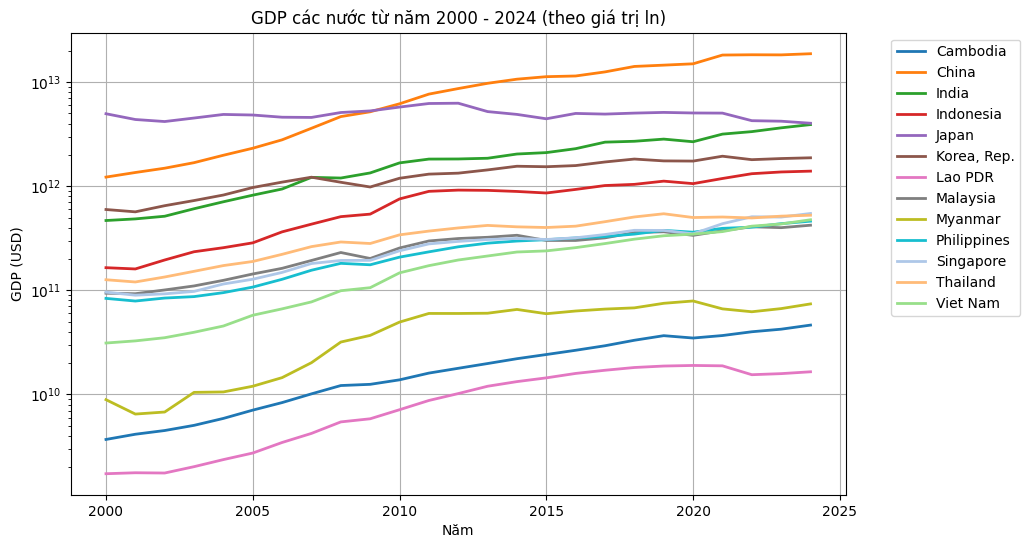

In [24]:
countries = data_GDP['Country Name'].unique()
plt.figure(figsize=(10,6))

for country, color in zip(countries, colors) :
    temp = data_GDP[data_GDP['Country Name'] == country]
    plt.plot(temp['Year'],temp['GDP (current US$)'],
             label = country, color = color, linewidth = 2)

plt.title("GDP các nước từ năm 2000 - 2024 (theo giá trị ln)")
plt.xlabel('Năm')
plt.ylabel('GDP (USD)')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

Nhận xét: Nhìn chung, GDP của hầu hết các nước đều tăng trong giai đoạn 2000-2024 nhưng với tốc độ khác nhau khi có những nước tăng ổn định, nhưng cũng có quốc gia có xu hướng tăng chậm và có dấu hiệu chững lại, có thể phân thành ba nhóm GDP như sau:
+ Nhóm GDP cao (từ $10^{12}$ USD trở lên): Trung Quốc có mức tăng trưởng nổi bật, từ khoảng hơn $10^{12}$ USD(năm 2000) lên hơn $10^{13}$ USD (năm 2024). Nhật Bản duy trì mức GDP cao và khá ổn định quanh $5.10^{12}$ USD, dù có vài giai đoạn giảm nhẹ. Ấn Độ cũng có xu hướng tăng đều từ $5.10^{11}$ USD lên gần $5.10^{12}$ USD. Hàn Quốc tăng ổn định trong nhiều năm trước khi có dấu hiệu giảm nhẹ từ 2023.

+ Nhóm GDP trung bình (từ $5.10^{10}$ USD đến $10^{12}$ USD):  Indonesia, Việt Nam là những quốc gia có tốc độ tăng trưởng GDP khá mạnh khi Indonesia từ $3.10^{11}$ USD (năm 2000) lên đến hơn $10^{12}$ USD (năm 2024) và Việt Nam đi từ $5.10^{10}$ USD (năm 2000) lên đến $5.10^{11}$ USD (năm 2024). Các nước như Thái Lan, Philippines, Malaysia và Singapore đều có tốc độ tăng trưởng gần như bằng nhau, tăng từ hơn $10^{11}$ USD (năm 2000) lên đến $5.10^{11}$ USD (năm 2024).

+ Nhóm GDP thấp (từ $5.10^{10}$ USD trở xuống): Các nước như Lào, Campuchia, Myanmar tuy GDP tăng dần theo thời gian nhưng vẫn nằm trong mức thấp ở giai đoạn 2000-2024, cách biệt hơn so với các nhóm khác.

Tiếp theo, chúng ta sẽ xem xét liệu dân số mỗi nước có tác động đáng kể đến GDP hay không, từ đó ảnh hưởng đến GDP bình quân đầu người và năng suất lao động như thế nào.


In [25]:
data_GDP_population = dfinal[['Country Name','Year','Population, total', 'GDP per capita (current US$)',
                              'GDP per person employed (constant 2021 PPP $)']]
data_GDP_population             

Series Name,Country Name,Year,"Population, total",GDP per capita (current US$),GDP per person employed (constant 2021 PPP $)
0,Cambodia,2000,12462336,296.426688,4190.721975
1,Cambodia,2001,12658484,327.500984,4353.422609
2,Cambodia,2002,12855241,350.147277,4482.398946
3,Cambodia,2003,13050968,386.691124,4793.447877
4,Cambodia,2004,13244731,444.199068,5079.446827
...,...,...,...,...,...
320,Viet Nam,2020,98079191,3534.039535,21529.549990
321,Viet Nam,2021,98935098,3704.193559,22095.631540
322,Viet Nam,2022,99680655,4147.697772,23264.776090
323,Viet Nam,2023,100352192,4323.350320,24333.248250


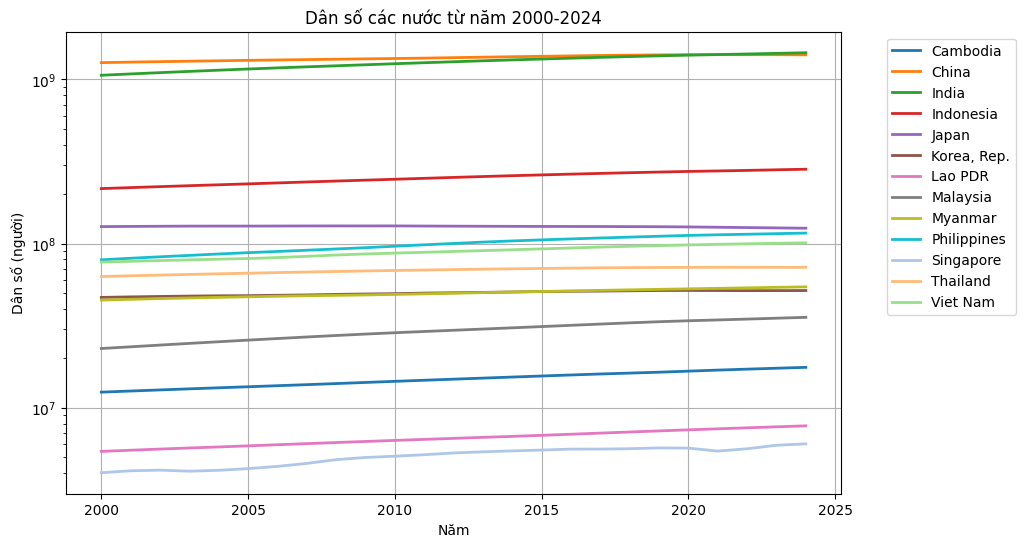

In [26]:
countries = data_GDP_population['Country Name'].unique()
plt.figure(figsize=(10,6))

for country, color in zip(countries, colors) :
    temp = data_GDP_population[data_GDP_population['Country Name'] == country]
    plt.plot(temp['Year'],temp['Population, total'],
             label = country, color = color, linewidth = 2)

plt.title("Dân số các nước từ năm 2000-2024")
plt.xlabel('Năm')
plt.ylabel('Dân số (người)')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

Nhận xét: Ta nhận thấy dân số hầu hết các nước đều tăng, nhưng với tốc độ và quy mô khác nhau trong giai đoạn 2000-2024, có thể chia thành 3 nhóm như sau:
- Nhóm dân số nhiều : Trong những quốc gia đang xét, Trung Quốc, Ấn Độ có quy mô dân số lớn đứng đầu và vẫn tăng ổn định trong những năm qua, dù tốc độ đã giảm dần ở những năm gần đây.

- Nhóm dân số trung bình: Gồm Indonesia, Nhật Bản, Philippines, Việt Nam, Hàn Quốc, Myanmar và Malaysia. Đặt biệt, Nhật Bản, Hàn Quốc đang có xu hướng già hóa dân số qua từng năm khi dân số ngày càng giảm theo từng năm. Ngược lại, các nước còn lại thì vẫn duy trì mức tăng tương đối ổn định.

- Nhóm dân số ít: Các nước như Lào, Campuchia, Singapore tuy quy mô vẫn còn thấp nhưng cũng cho thấy sự tăng trưởng dân số đều đặn qua từng năm.

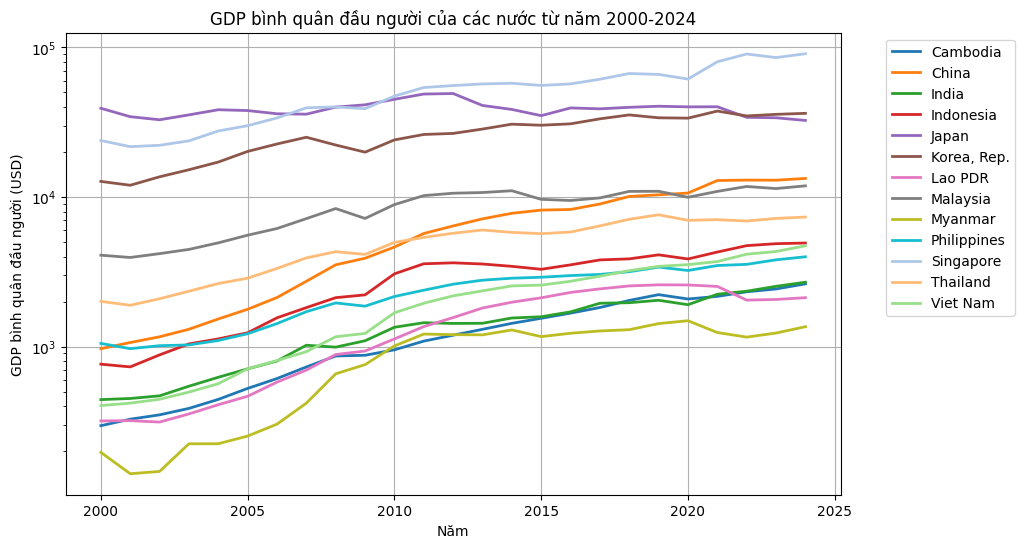

In [27]:
countries = data_GDP_population['Country Name'].unique()
plt.figure(figsize=(10,6))

for country, color in zip(countries, colors) :
    temp = data_GDP_population[data_GDP_population['Country Name'] == country]
    plt.plot(temp['Year'],temp['GDP per capita (current US$)'],
             label = country, color = color, linewidth = 2)

plt.title("GDP bình quân đầu người của các nước từ năm 2000-2024")
plt.xlabel('Năm')
plt.ylabel('GDP bình quân đầu người (USD)')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

Nhận xét: Nhìn chung, GDP bình quân đầu người của các nước đều có xu hướng tăng trong giai đoạn 2000–2024, nhưng tốc độ tăng trưởng giữa các quốc gia có sự khác biệt rõ rệt.

- Singapore, Nhật Bản và Hàn Quốc luôn duy trì mức GDP bình quân từ khoảng 10,000 USD đến gần 100,000 USD . Trong nhóm này, Singapore tăng nhanh và ổn định nhất, liên tục mở rộng khoảng cách so với các nước còn lại. Nhật Bản gần như đi ngang trong suốt giai đoạn do tăng trưởng kinh tế thấp và quá trình già hóa dân số. Hàn Quốc tiếp tục tăng đều và bám sát Nhật Bản, nhưng giảm rất nhanh vào năm 2023.

- Trung Quốc, Việt Nam và Malaysia nổi bật với mức tăng nhanh và liên tục, thu hẹp khoảng cách với nhóm trên. Trung Quốc và Việt Nam đặc biệt cho thấy sự cải thiện rõ rệt qua từng năm.  Ấn Độ , Indonesia, Philippines và Thái Lan duy trì xu hướng tăng nhưng với tốc độ vừa phải. 

- Lào, Campuchia và Myanmar có mức GDP đầu người thấp hơn các nước còn lại nhưng vẫn tăng ổn định, phản ánh sự cải thiện dần trong nền kinh tế.

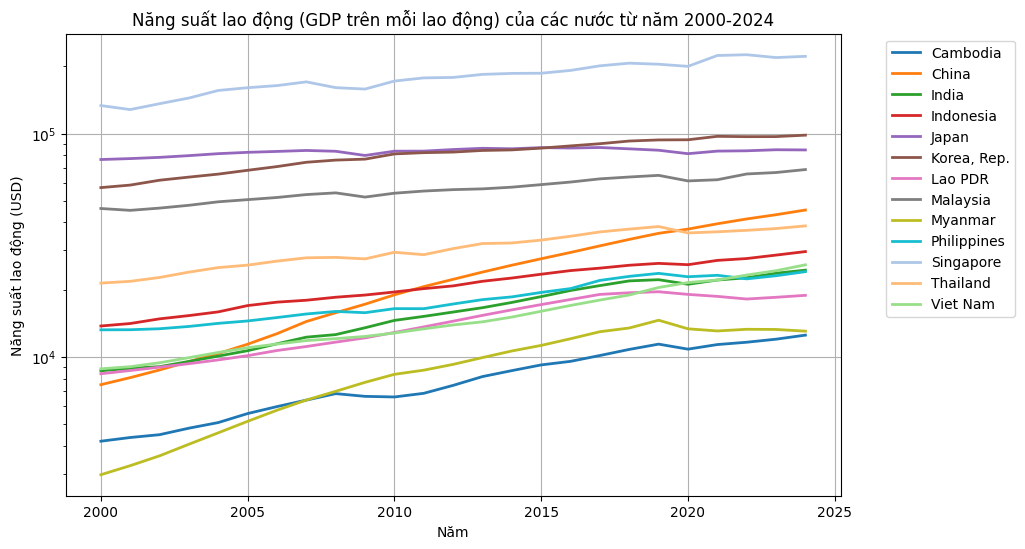

In [28]:
countries = data_GDP_population['Country Name'].unique()
plt.figure(figsize=(10,6))

for country, color in zip(countries, colors) :
    temp = data_GDP_population[data_GDP_population['Country Name'] == country]
    plt.plot(temp['Year'],temp['GDP per person employed (constant 2021 PPP $)'],
             label = country, color = color, linewidth = 2)

plt.title("Năng suất lao động (GDP trên mỗi lao động) của các nước từ năm 2000-2024")
plt.xlabel('Năm')
plt.ylabel('Năng suất lao động (USD)')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

Nhận xét: Ta nhận thấy năng suất của hầu hết các nước đều tăng theo thời gian, nhưng mức độ tăng trưởng và tốc độ có sự khác nhau rõ rệt, với:

- Singapore, Nhật Bản và Hàn Quốc luôn đứng đầu trong giai đoạn 2000-2024, với Singapore vượt trội nhất khi luôn giữ mức hơn 100,000 USD và vẫn còn tăng đều theo từng năm. Nhật Bản ổn định ở mức cao nhưng có xu hướng chững lại, phản ánh tốc độ tăng trưởng kinh tế thấp và lực lượng lao động già hóa. Trong khi đó, Hàn Quốc tăng đều nhưng chậm hơn Singapore, liên tục bám sát Nhật Bản, nhưng bắt đầu giảm rất nhanh vào khoảng năm 2023.

- Trung Quốc, Việt Nam, Ấn Độ cũng cho thấy mức tăng năng suất lao động mạnh mẽ và liên tục qua mỗi năm. Trong đó, Trung Quốc tăng nhanh một cách rõ rệt khi từ dưới 10,000 USD lên đến 50,000 USD. Việt Nam và Ấn Độ cũng tăng ổn định và tương đối đều qua từng năm khi tăng từ khoảng 10,000 USD lên tới 20,000 USD.

- Malaysia, Thái Lan, Indonesia và Philippines cũng duy trì xu hướng tăng năng suất nhưng với tốc độ vừa phải. Malaysia có mức năng suất cao nhất trong 4 nước và tăng khá ổn định, 3 nước còn lại tuy năng suất vẫn tăng đều nhưng lại tương đối ổn định, không quá đột phá.

- Lào, Campuchia và Myanmar là những nước có năng suất thấp nhất trong các nước đang xét. Tuy vậy, cả ba nước đều bắt đầu tăng năng suất lao động với Campuchia và Myanmar tăng rất mạnh từ khoảng 2000-2019,dù Myanmar bắt đầu giảm nhẹ từ năm 2020.

Để thấy rõ tác động của dân số và năng suất lao động đến sự tăng trưởng GDP của các nước như thế nào, ta sẽ vẽ thêm biểu đồ scatter với độ lớn các điểm dựa vào dân số mỗi nước.

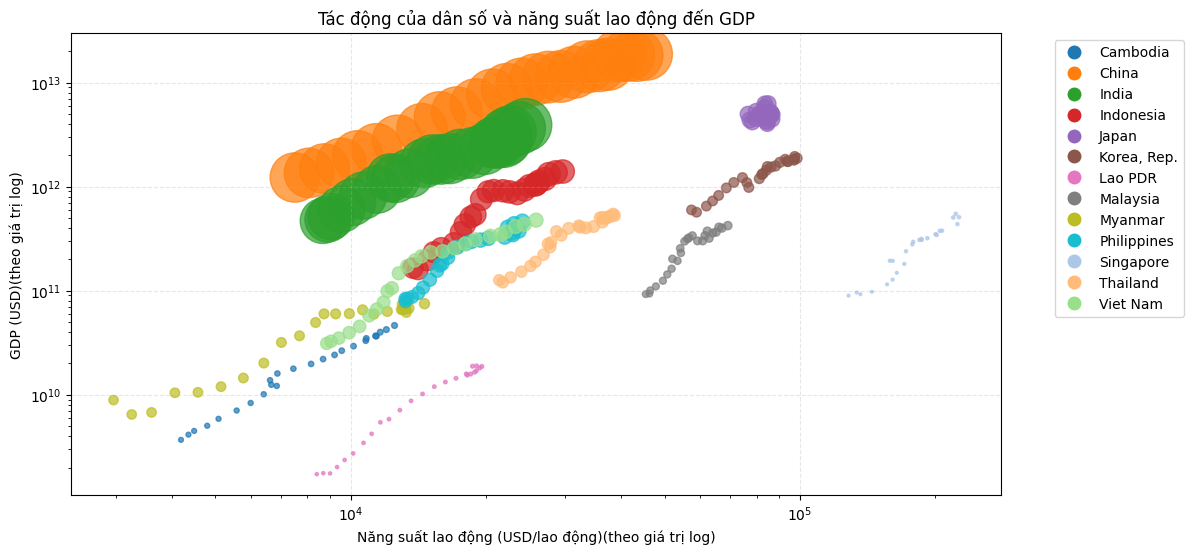

In [29]:
area = 1e-8 * dfinal['Population, total']
countries = dfinal['Country Name'].unique()
plt.figure(figsize=(12,6))
for country, c in zip(countries, colors):
    temp = dfinal[dfinal['Country Name'] == country]
    plt.scatter(temp['GDP per person employed (constant 2021 PPP $)'], temp['GDP (current US$)'], 
                color=c, alpha=0.7, s= temp['Population, total'] * 1e-6) 
plt.yscale('log')
plt.xscale('log')
plt.title('Tác động của dân số và năng suất lao động đến GDP')
plt.xlabel("Năng suất lao động (USD/lao động)(theo giá trị log)")
plt.ylabel("GDP (USD)(theo giá trị log)")
plt.grid(True, linestyle='--', alpha=0.3)
# tạo legend riêng để các chấm trong legend đồng đều hơn
legend_handles = [
    mlines.Line2D([], [], color=c, marker='o', linestyle='None',
                  markersize=9, label=country)
    for country, c in zip(countries, colors)
]

plt.legend(handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

Kết luận: Ta nhận thấy năng suất lao động là yếu tố quyết định đến quá trình tăng trưởng GDP của các nước. Ví dụ như Singapore, tuy có dân số rất ít nhưng do năng suất cao (trên $10^5$ USD/ lao động) nên quốc gia này có GDP nằm ở mức cao (trên $10^{11}$ USD). Song cũng không thể phủ nhận vai trò của dân số trong việc duy trì ổn định GDP, như Trung Quốc và Ấn Độ dù năng suất lao động nằm ở mức trung bình nhưng do dân số đông nên GDP rất lớn (nằm trong khoảng $10^{12}$ đến $10^{13}$ USD). Tóm lại, cả dân số và năng suất lao động đều ảnh hưởng đến GDP, nhưng **năng suất lao động mới là yếu tố quyết định chất lượng và tốc độ phát triển GDP trong dài hạn.**

Ta cũng kiểm tra xem cơ cấu các ngành kinh tế (nông nghiệp, công nghiệp, dịch vụ) để thấy được các ngành ảnh hưởng đến GDP của các nước như thế nào. 

In [30]:
data_sector = dfinal[['Country Name','Year',
                      'Agriculture, forestry, and fishing, value added (% of GDP)',
                      'Industry (including construction), value added (% of GDP)',
                      'Services, value added (% of GDP)', 'GDP (current US$)']]
data_sector

Series Name,Country Name,Year,"Agriculture, forestry, and fishing, value added (% of GDP)","Industry (including construction), value added (% of GDP)","Services, value added (% of GDP)",GDP (current US$)
0,Cambodia,2000,35.527736,21.645599,36.714563,3.694169e+09
1,Cambodia,2001,32.965377,23.264626,38.057669,4.145666e+09
2,Cambodia,2002,29.611005,25.379306,38.999121,4.501228e+09
3,Cambodia,2003,29.474380,26.342875,38.730250,5.046693e+09
4,Cambodia,2004,26.628663,27.680269,39.444036,5.883297e+09
...,...,...,...,...,...,...
320,Viet Nam,2020,12.655404,36.743713,41.831160,3.466160e+11
321,Viet Nam,2021,12.603090,37.391519,41.257440,3.664750e+11
322,Viet Nam,2022,11.880300,38.482361,41.135642,4.134450e+11
323,Viet Nam,2023,11.861671,37.581570,42.294228,4.338580e+11


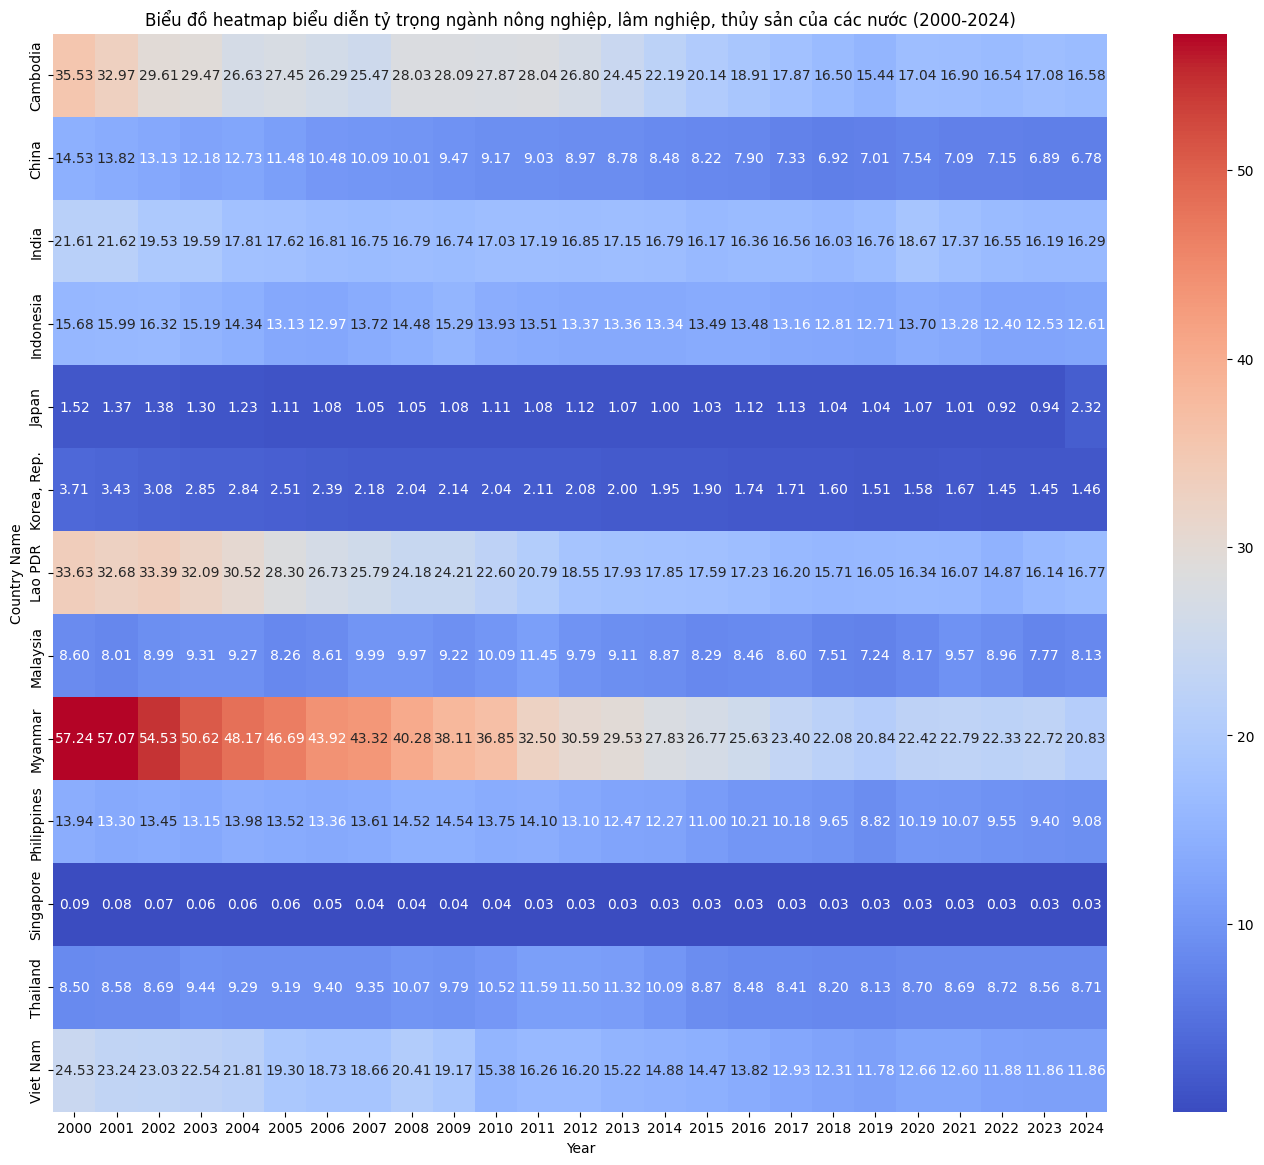

In [31]:
sector1 = 'Agriculture, forestry, and fishing, value added (% of GDP)'
df_heat1 = data_sector.pivot(index = 'Country Name', columns='Year', values=sector1)
plt.figure(figsize=(17,14))
sns.heatmap(df_heat1, cmap='coolwarm', annot = True,fmt='.2f')
plt.title("Biểu đồ heatmap biểu diễn tỷ trọng ngành nông nghiệp, " \
"lâm nghiệp, thủy sản của các nước (2000-2024)")
plt.show()

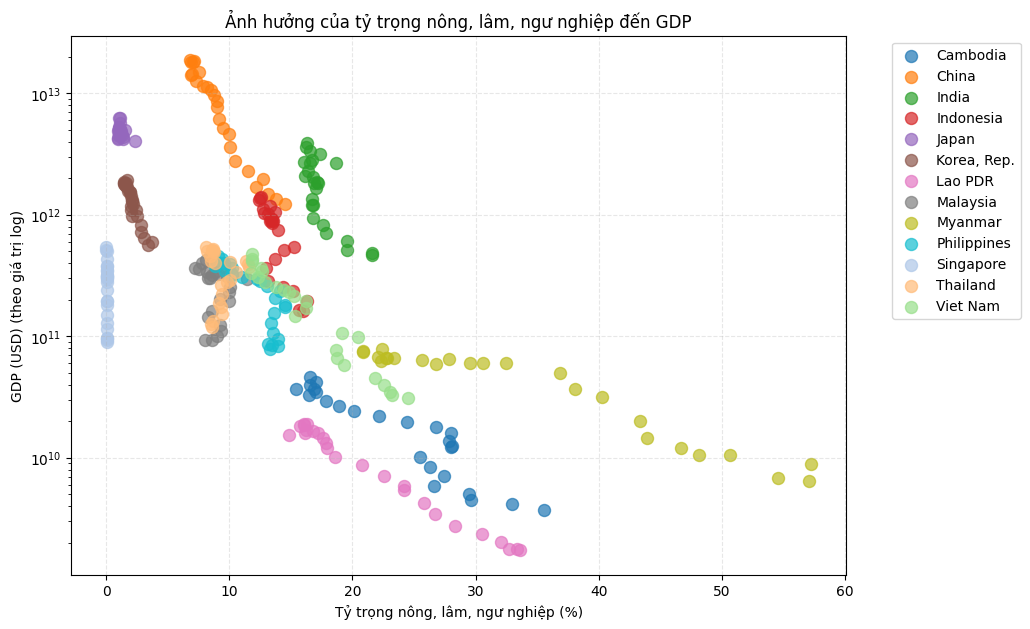

In [32]:
plt.figure(figsize=(10,7))

countries = data_sector['Country Name'].unique()

for country, c in zip(countries, colors):
    temp = data_sector[data_sector['Country Name'] == country]
    plt.scatter(temp['Agriculture, forestry, and fishing, value added (% of GDP)'], temp['GDP (current US$)'], 
                label=country, color=c, alpha=0.7, s= 75)
plt.title("Ảnh hưởng của tỷ trọng nông, lâm, ngư nghiệp đến GDP")
plt.xlabel("Tỷ trọng nông, lâm, ngư nghiệp (%)")
plt.ylabel("GDP (USD) (theo giá trị log)")
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 


plt.show()


Nhận xét: Tỷ trọng nông, lâm, ngư nghiệp bắt đầu giảm liên tục trong giai đoạn 2000 - 2024, thể hiện rõ nhất qua sự thay đổi màu sắc từ đỏ sang xanh ở hầu hết các quốc gia, cho thấy được quá trình công nghiệp hóa và hiện đại hóa, cũng như sự chuyển dịch lao động và nguồn lực sang các ngành có giá trị tăng cao hơn (công nghiệp, dịch vụ).

+ Ở nhóm nước như Trung Quốc, Malaysia, Indonesia, Việt Nam, Campuchia, Thái Lan, Myanmar, Lào và Ấn Độ, tỷ trọng nông nghiệp giảm rất mạnh.
Ví dụ: Myanmar giảm từ 57,24% (2000) xuống còn 20,83% (2024) – mức giảm sâu nhất trong nhóm.

+ Trong khi đó, các nước Nhật Bản, Hàn Quốc, Singapore luôn duy trì tỷ trọng nông nghiệp rất thấp (dưới 5%), phản ánh nền kinh tế đã phát triển cao và phụ thuộc chủ yếu vào công nghiệp – dịch vụ.

+ Ảnh hưởng của nông, lâm, ngư nghiệp đến GDP: Ta quan sát thấy rằng tỷ trọng nông, lâm, ngư nghiệp càng cao thì GDP bình quân đầu người càng thấp. Các quốc gia có tỷ trọng nông nghiệp lớn — như Campuchia, Lào, Myanmar hay Việt Nam (giai đoạn đầu) — đều có mức GDP thấp trong nhiều năm. Ngược lại, những nước có tỷ trọng nông nghiệp rất nhỏ, tiêu biểu như Singapore (gần như bằng 0% trong suốt giai đoạn quan sát), lại đạt mức GDP bình quân đầu người rất cao, vượt xa phần còn lại của khu vực.

Điều này phản ánh xu hướng chung: **Khi nền kinh tế thoát khỏi phụ thuộc vào nông nghiệp và chuyển dịch sang công nghiệp – dịch vụ có giá trị gia tăng cao, GDP sẽ tăng mạnh.**

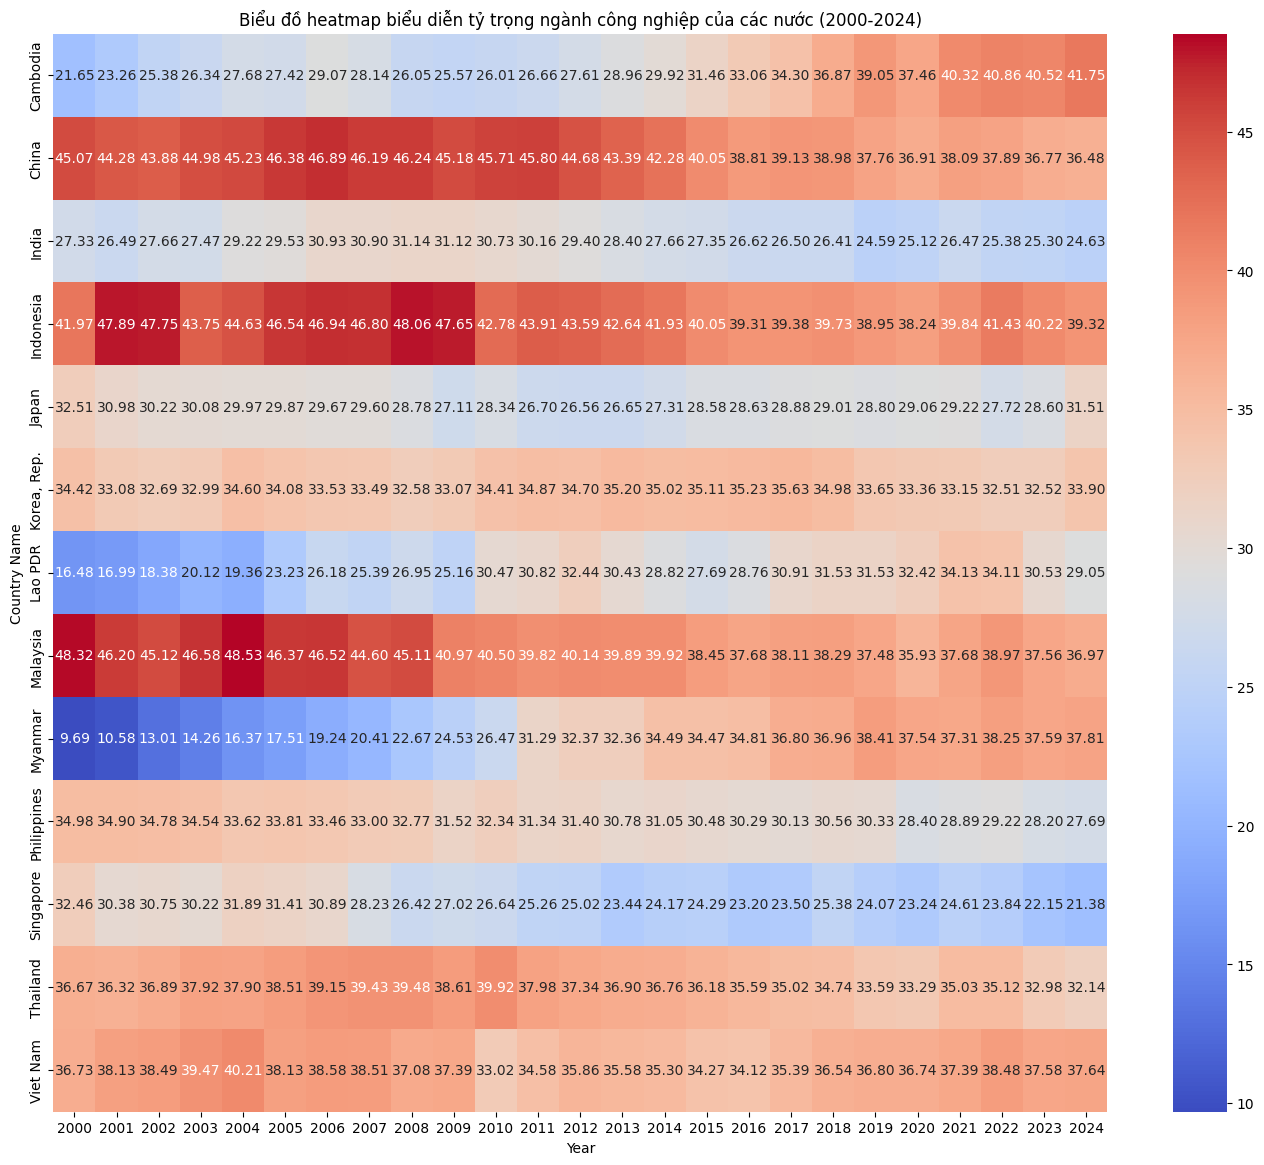

In [33]:
sector2 = 'Industry (including construction), value added (% of GDP)'
df_heat2 = data_sector.pivot(index = 'Country Name', columns='Year', values=sector2)
plt.figure(figsize=(17,14))
sns.heatmap(df_heat2, cmap='coolwarm', annot = True,fmt='.2f')
plt.title("Biểu đồ heatmap biểu diễn tỷ trọng ngành công nghiệp của các nước (2000-2024)")
plt.show()

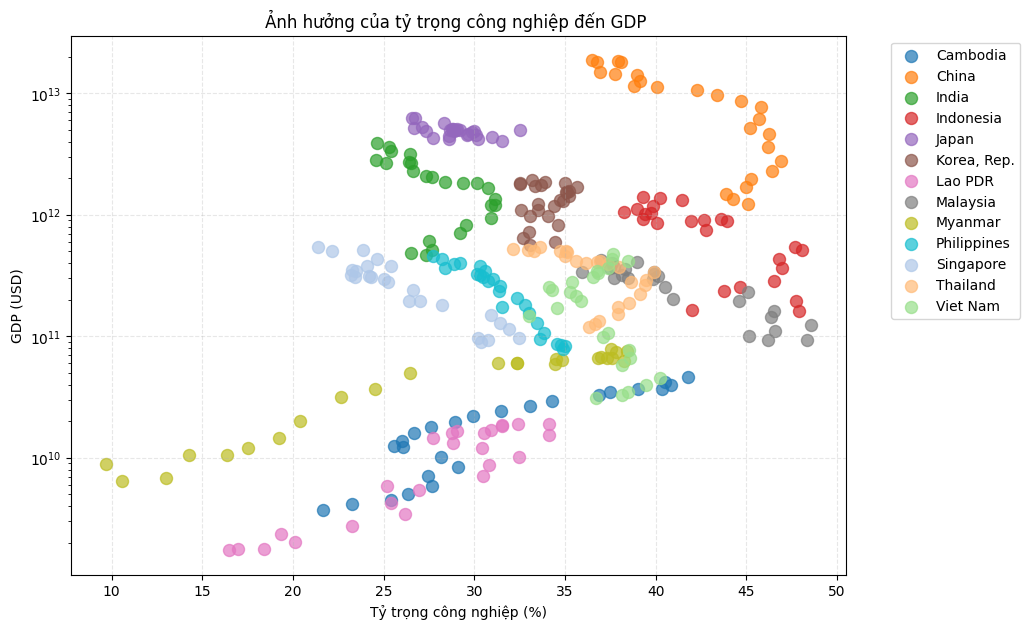

In [34]:
plt.figure(figsize=(10,7))

countries = data_sector['Country Name'].unique()

for country, c in zip(countries, colors):
    temp = data_sector[data_sector['Country Name'] == country]
    plt.scatter(temp['Industry (including construction), value added (% of GDP)'], temp['GDP (current US$)'], 
                label=country, color=c, alpha=0.7, s= 75)

plt.title("Ảnh hưởng của tỷ trọng công nghiệp đến GDP ")
plt.xlabel("Tỷ trọng công nghiệp (%)")
plt.ylabel("GDP (USD)")
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 

plt.show()


Nhận xét: Nhìn chung, tỷ trọng công nghiệp ở nhiều nước đều có xu hướng giảm theo từng năm.

+ Một số nước như Campuchia, Lào, Myanmar duy trì việc tăng liên tục tỷ trọng công nghiệp qua mỗi năm. Trong đó, Campuchia tăng liên tục từ 20,65% (2000) lên đến 41,65% (2024), Myanmar tăng liên tục từ 9,64% (2000) đến 37,81% (2024), Lào cũng tăng liên tục từ 16,48% (2024) lên đến 30,64% (2023). 

+ Tuy vậy hầu hết các nước còn lại đang có xu hướng chững lại hoặc bắt đầu giảm như Việt Nam có tỷ trọng gần như ổn định qua các năm ở ngưỡng 36-37% và có giảm nhẹ ở một số năm ; Malaysia bắt đầu giảm liên tục từ 48,32% (2000) xuống còn 37,07% (2024) ; Trung Quốc cũng bắt đầu giảm liên tục từ 45,07% (2000) xuống còn 36,48% (2024) ; ...

+ Ảnh hưởng của công nghiệp đến GDP: Nhìn chung, GDP bình quân đầu người có xu hướng tăng khi các nước giảm dần tỷ trọng công nghiệp và chuyển dịch mạnh sang khu vực dịch vụ. Điều này thể hiện rõ ở các nước như Trung Quốc, Ấn Độ, Indonesia, Việt Nam hay Singapore: dù tỷ trọng công nghiệp giảm nhẹ theo thời gian, GDP vẫn tiếp tục tăng mạnh. Tuy nhiên, vẫn tồn tại một số trường hợp như Myanmar hay Campuchia, nơi tỷ trọng công nghiệp tiếp tục tăng nhưng GDP cũng tăng theo, cho thấy công nghiệp vẫn đóng vai trò quan trọng ở giai đoạn đầu phát triển.

Từ đó có thể kết luận rằng: **Tỷ trọng công nghiệp không phải là yếu tố quyết định mức GDP cao hay thấp. Tăng trưởng GDP phụ thuộc nhiều hơn vào việc nền kinh tế chuyển dịch sang dịch vụ có giá trị gia tăng cao, trong khi công nghiệp chỉ là động lực quan trọng ở giai đoạn công nghiệp hóa, không đảm bảo GDP cao về dài hạn.**

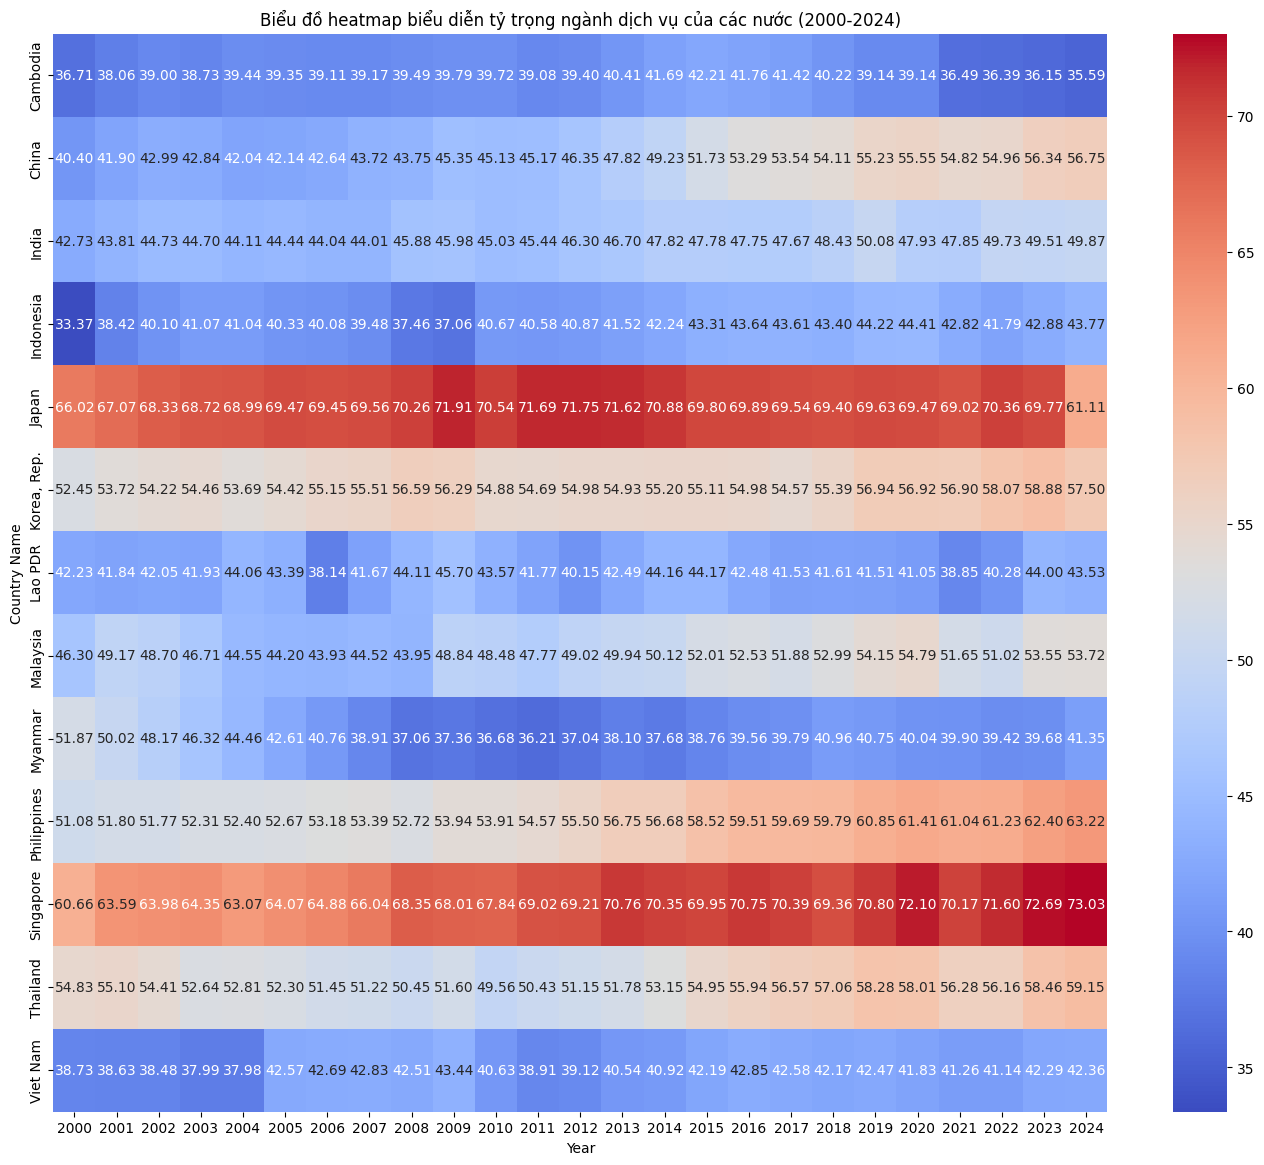

In [35]:
sector3 = 'Services, value added (% of GDP)'
df_heat3 = data_sector.pivot(index = 'Country Name', columns='Year', values=sector3)
plt.figure(figsize=(17,14))
sns.heatmap(df_heat3, cmap='coolwarm', annot = True,fmt='.2f')
plt.title("Biểu đồ heatmap biểu diễn tỷ trọng ngành dịch vụ của các nước (2000-2024)")
plt.show()

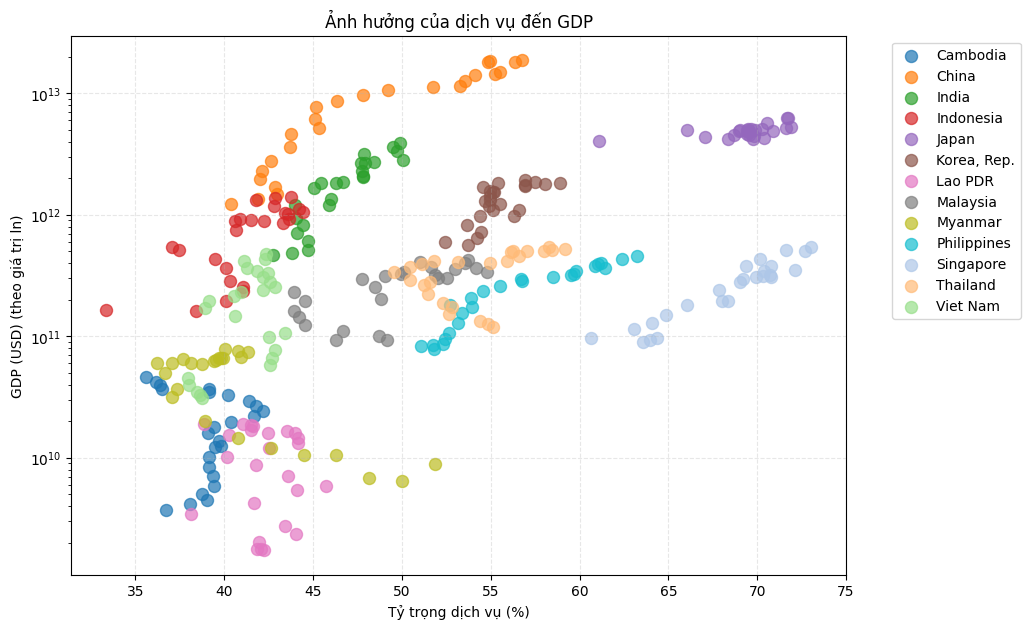

In [36]:
plt.figure(figsize=(10,7))

countries = data_sector['Country Name'].unique()

for country, c in zip(countries, colors):
    temp = data_sector[data_sector['Country Name'] == country]
    plt.scatter(temp['Services, value added (% of GDP)'], temp['GDP (current US$)'], 
                label=country, color=c, alpha=0.7, s= 75)

plt.title("Ảnh hưởng của dịch vụ đến GDP")
plt.xlabel("Tỷ trọng dịch vụ (%)")
plt.ylabel("GDP (USD) (theo giá trị ln)")
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()


Nhận xét: Ta nhận thấy hầu hết các nước đều tăng và duy trì tỷ trọng dịch vụ ở mức cao (từ 50-70% ở nhiều nước), biểu hiện qua sự chuyển đổi màu sắc từ xanh đậm qua xanh nhạt và qua đỏ nhạt, đỏ đậm.

+ Các nước như Thái Lan, Myanmar, Malaysia, Indonesia, Lào, Hàn Quốc, Nhật Bản, Việt Nam và Campuchia tuy có giảm nhẹ ở một số năm nhưng nhìn chung tỷ trọng các nước này vẫn tăng và nằm ở mức khá cao (từ 30-40%), thậm chí nằm ở mức cao như Hàn Quốc và Nhật Bản (thường nằm trên 60-70%).

+ Những nước còn lại như Singapore, Philippines, Nhật Bản, Ấn Độ và Trung Quốc luôn duy trì ổn định đà tăng trưởng tỷ trọng dịch vụ qua từng năm. Trong đó, Singapore luôn duy trì ở mức cao, thường nằm ở mức 60-70%.

+ Ảnh hưởng của dịch vụ đến GDP: Khi tỷ trọng dịch vụ tăng và chiếm ưu thế, GDP của các nước cũng có xu hướng tăng tương ứng. Điều này phù hợp với thực tế rằng dịch vụ thường đóng vai trò động lực chính trong tăng trưởng kinh tế hiện đại, đặc biệt ở các nền kinh tế đã hoặc đang công nghiệp hóa $\Rightarrow$ **dịch vụ là nhân tố quan trọng quyết định sự tăng trưởng lâu dài của GDP.**

Kết luận:

⇒ **Trong quá trình phát triển, các nước có xu hướng chuyển dịch cơ cấu từ nông nghiệp sang công nghiệp và dịch vụ. Dịch vụ tăng mạnh không chỉ phản ánh mức độ hiện đại hóa mà còn là động lực làm GDP tăng trưởng.**

Mặt khác, ta cũng cần xem xét liệu hoạt động xuất nhập khẩu có tác động đáng kể đến GDP hay không.


In [37]:
data_export_import = dfinal[['Country Name','Year','GDP (current US$)',
                            'Exports of goods and services (% of GDP)',
                            'Imports of goods and services (% of GDP)']]
data_export_import

Series Name,Country Name,Year,GDP (current US$),Exports of goods and services (% of GDP),Imports of goods and services (% of GDP)
0,Cambodia,2000,3.694169e+09,49.304900,61.092225
1,Cambodia,2001,4.145666e+09,51.179775,60.591966
2,Cambodia,2002,4.501228e+09,54.188950,64.080612
3,Cambodia,2003,5.046693e+09,54.228624,65.846345
4,Cambodia,2004,5.883297e+09,60.818357,70.533124
...,...,...,...,...,...
320,Viet Nam,2020,3.466160e+11,84.381598,78.864265
321,Viet Nam,2021,3.664750e+11,93.850207,92.825626
322,Viet Nam,2022,4.134450e+11,93.420129,89.733490
323,Viet Nam,2023,4.338580e+11,86.467419,78.350652


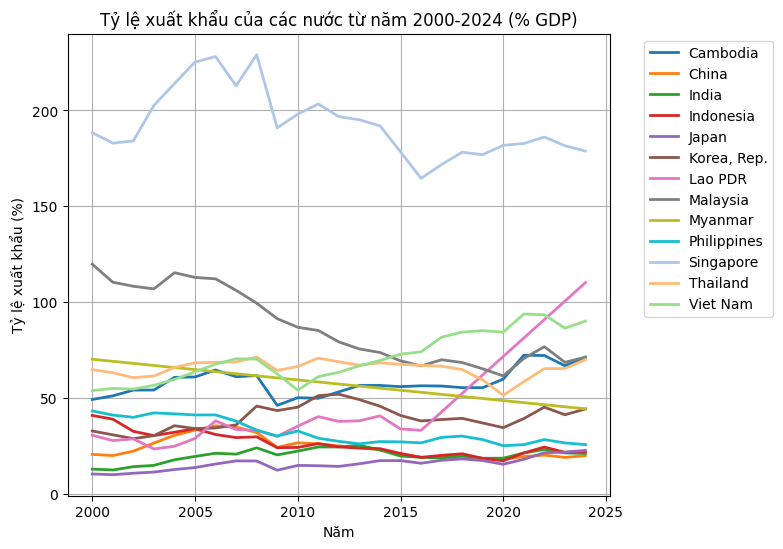

In [38]:
countries = data_export_import['Country Name'].unique()

plt.figure(figsize=(7,6))

for country, color in zip(countries, colors) :
    temp = data_export_import[data_export_import['Country Name'] == country]
    plt.plot(temp['Year'],temp['Exports of goods and services (% of GDP)'],
             label = country, color = color, linewidth = 2)

plt.title("Tỷ lệ xuất khẩu của các nước từ năm 2000-2024 (% GDP)")
plt.xlabel('Năm')
plt.ylabel('Tỷ lệ xuất khẩu (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

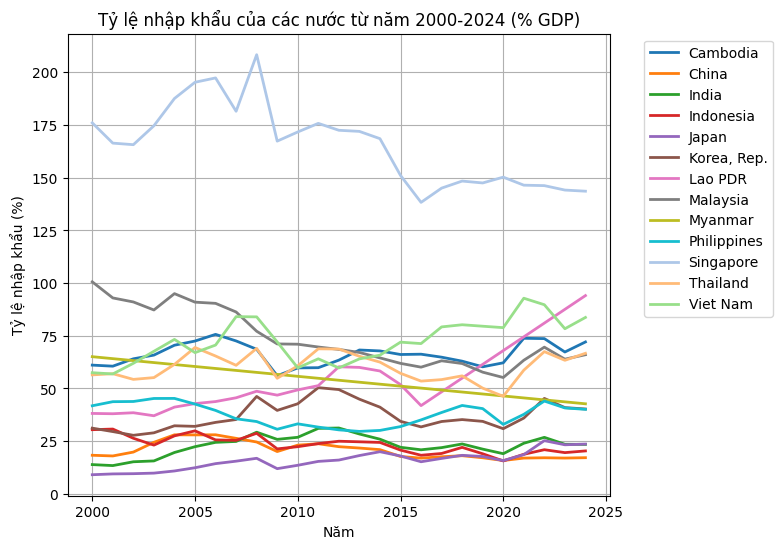

In [39]:
countries = data_export_import['Country Name'].unique()

plt.figure(figsize=(7,6))

for country, color in zip(countries, colors) :
    temp = data_export_import[data_export_import['Country Name'] == country]
    plt.plot(temp['Year'],temp['Imports of goods and services (% of GDP)'],
             label = country, color = color, linewidth = 2)

plt.title("Tỷ lệ nhập khẩu của các nước từ năm 2000-2024 (% GDP)")
plt.xlabel('Năm')
plt.ylabel('Tỷ lệ nhập khẩu (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

Như vậy, biểu đồ cho thấy sự khác biệt rất lớn về mức độ phụ thuộc vào xuất khẩu, nhập khẩu giữa các nền kinh tế trong khu vực, trong đó:

- Xuất khẩu:
    - Singapore nổi bật với tỷ lệ xuất khẩu trên GDP cực kỳ cao, luôn duy trì trên 150% và có lúc vượt 200%, khẳng định vai trò là trung tâm tái xuất khẩu và trung chuyển hàng hóa toàn cầu của nước này.

    - Các nước ASEAN như Malaysia, Việt Nam, Thái Lan, và Campuchia thuộc nhóm có mức độ mở cửa kinh tế cao, duy trì tỷ lệ xuất khẩu ở mức 50–100% GDP. Đặc biệt, Việt Nam thể hiện xu hướng tăng mạnh liên tục trong suốt giai đoạn, là minh chứng rõ ràng cho quá trình hội nhập và phát triển thành trung tâm sản xuất mới.

    - Các nền kinh tế lớn, hướng nội địa như Nhật Bản, Ấn Độ, Hàn Quốc và Trung Quốc (mặc dù là cường quốc xuất khẩu) lại duy trì tỷ lệ xuất khẩu/GDP ở mức thấp nhất (khoảng 10–30%). Tỷ lệ này cho thấy tăng trưởng GDP của họ chủ yếu dựa vào tiêu dùng và đầu tư nội địa hơn là ngoại thương.

- Nhập khẩu:
    - Singapore cũng nổi bật với tỷ lệ nhập khẩu trên GDP rất cao (thường trên 150% - 200% GDP), khẳng định một lần nữa vai trò là trung tâm trung chuyển và thương mại quốc tế của quốc gia này.

    - Các nước thuộc nhóm có mức độ mở cửa kinh tế cao (Malaysia, Việt Nam, Thái Lan, và Campuchia) cũng duy trì tỷ lệ Nhập khẩu ở mức 50 – 100% GDP và biến động song hành với xuất khẩu. Đặc biệt, Việt Nam thể hiện xu hướng tăng mạnh liên tục, điều này phản ánh nhu cầu lớn về nhập khẩu nguyên vật liệu và máy móc để phục vụ cho quá trình sản xuất và xuất khẩu.

    - Các nền kinh tế lớn như Ấn Độ, Nhật Bản, Hàn Quốc và Trung Quốc cũng duy trì tỷ lệ nhập khẩu/GDP ở mức thấp nhất (khoảng 10 – 30%), tương đồng với tỷ lệ xuất khẩu. Tỷ lệ này cho thấy tính tự chủ kinh tế cao và tăng trưởng GDP của họ chủ yếu dựa vào tiêu dùng và đầu tư nội địa hơn là dựa vào chuỗi cung ứng quốc tế.

Kết luận: Các biểu đồ Xuất khẩu và Nhập khẩu (% GDP) đã phản ánh rõ nét sự phân hóa và mức độ hội nhập kinh tế rất khác nhau giữa các quốc gia trong khu vực 2000 - 2025. Biểu đồ phản ánh mức độ hội nhập kinh tế và vai trò thương mại rất khác nhau trong khu vực, có thể phân thành hai nhóm như sau :

- Nhóm Hướng Ngoại (Nền kinh tế Mở cửa Sâu) : Các nước hướng ngoại và đóng vai trò là trung tâm thương mại/sản xuất (như Singapore, Malaysia, Việt Nam, Thái Lan, Campuchia) có tỷ lệ Xuất khẩu/Nhập khẩu trên GDP rất cao (thường từ 50% đến hơn 200%). Tăng trưởng GDP của nhóm này phụ thuộc lớn vào thị trường toàn cầu.

- Nhóm Hướng Nội (Nền kinh tế Tự chủ) : Các nước có thị trường nội địa lớn hoặc đã phát triển ổn định (Trung Quốc, Indonesia, Nhật Bản, Hàn Quốc, Ấn Độ) có tỷ trọng Xuất khẩu/Nhập khẩu trên GDP thấp hơn (thường dưới 40%). Điều này cho thấy tăng trưởng GDP của họ chủ yếu dựa vào tiêu dùng và đầu tư nội địa, và có tính tự chủ cao hơn trước các cú sốc bên ngoài.

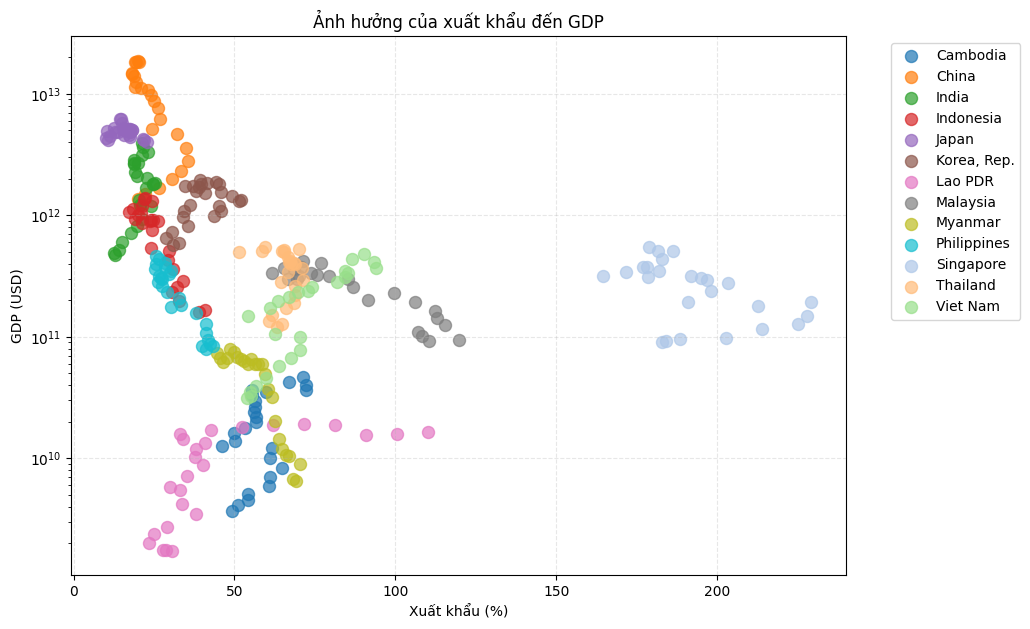

In [40]:
plt.figure(figsize=(10,7))

countries = data_export_import['Country Name'].unique()

for country, c in zip(countries, colors):
    temp = data_export_import[data_export_import['Country Name'] == country]
    plt.scatter(temp['Exports of goods and services (% of GDP)'], temp['GDP (current US$)'], 
                label=country, color=c, alpha=0.7, s= 75)

plt.title("Ảnh hưởng của xuất khẩu đến GDP")
plt.xlabel("Xuất khẩu (%)")
plt.ylabel("GDP (USD)")
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()
                

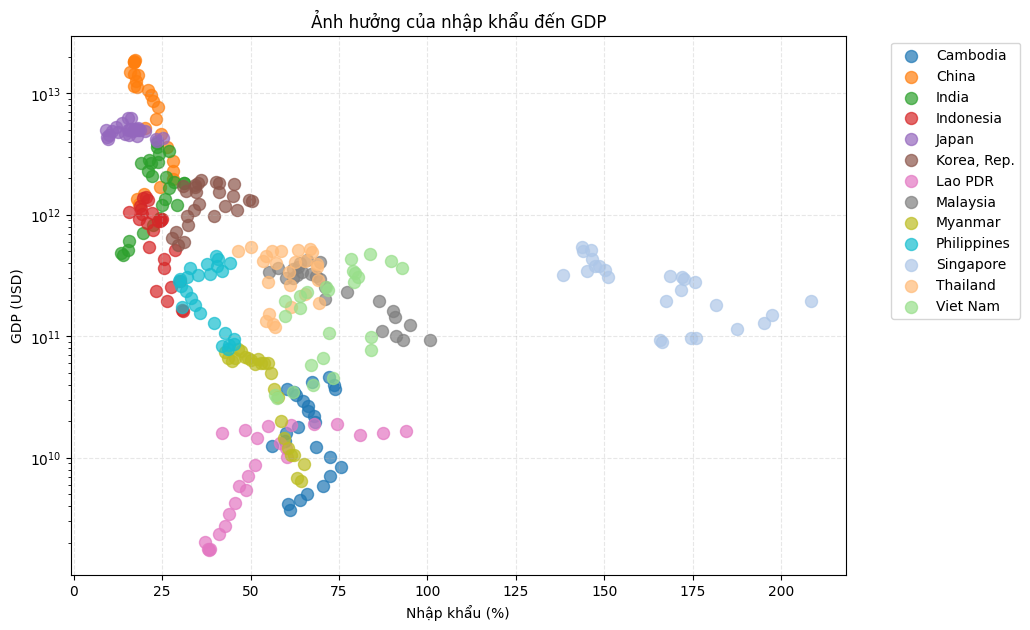

In [41]:
plt.figure(figsize=(10,7))

countries = data_export_import['Country Name'].unique()

for country, c in zip(countries, colors):
    temp = data_export_import[data_export_import['Country Name'] == country]
    plt.scatter(temp['Imports of goods and services (% of GDP)'], temp['GDP (current US$)'], 
                label=country, color=c, alpha=0.7, s= 75)

plt.title("Ảnh hưởng của nhập khẩu đến GDP")
plt.xlabel("Nhập khẩu (%)")
plt.ylabel("GDP (USD)")
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()


Ta nhận thấy xuất khẩu và nhập khẩu đều không có mối quan hệ quyết định trực tiếp đến quy mô GDP. Cụ thể, có những quốc gia tuy có tỷ lệ xuất khẩu hoặc nhập khẩu rất cao nhưng GDP chỉ ở mức trung bình hoặc không quá lớn (như Singapore, Malaysia, Campuchia, Myanmar); ngược lại, một số quốc gia dù tỷ lệ xuất khẩu và nhập khẩu không cao nhưng lại sở hữu GDP rất lớn (như Trung Quốc, Ấn Độ, Nhật Bản và Hàn Quốc).

$\Rightarrow$ **Xuất khẩu và nhập khẩu không phải là yếu tố quyết định sự phát triển GDP của mỗi quốc gia.**

### 3. Dự đoán dữ liệu GDP:
#### a. Kiểm định giả thuyết:


Dựa trên kết quả phân tích dữ liệu, ta sẽ tiến hành huấn luyện mô hình dự báo để ước tính xu hướng tăng trưởng GDP của các quốc gia trong tương lai. Nhưng trước hết, ta cần kiểm định mức độ ảnh hưởng thống kê của các yếu tố kinh tế – xã hội sau đây đến GDP:

| Biến | Mô tả |
|---|---|
| Agriculture, forestry, and fishing, value added (% of GDP) | Tỷ lệ nông, lâm, ngư nghiệp (% GDP) |
| Exports of goods and services (% of GDP) | Tỷ lệ xuất khẩu (% GDP) |
| GDP per person employed (constant 2021 PPP $) | GDP bình quân trên lao động (năng suất lao động) |
| Imports of goods and services (% of GDP) | Tỷ lệ nhập khẩu (% GDP) |
| Industry (including construction), value added (% of GDP) | Tỷ lệ công nghiệp (% GDP) |
| Population, total | Dân số (người) |
| Services, value added (% of GDP) | Tỷ lệ dịch vụ (% GDP) |

Ta quan tâm các biến có ảnh hưởng đến mô hình dự đoán, nên ta sẽ tạo ra cặp giả thuyết - đối thuyết như sau để xác định các biến có ý nghĩa thống kê, làm cơ sở để lựa chọn đặc trưng (feature selection) cho mô hình:

* $H_0$ : Hệ số hồi quy của biến bằng 0 ($\beta_i = 0$). Biến độc lập không có ảnh hưởng đến GDP.
* $H_1$ : Hệ số hồi quy của biến khác 0 ($\beta_i \neq 0$). Biến độc lập có ảnh hưởng ý nghĩa thống kê đến GDP.

Để làm được điều đó, ta sẽ sử dụng hệ số tương quan Pearson (Pearson correlation coefficient) để đánh giá mức độ liên hệ tuyến tính giữa từng biến độc lập với biến phụ thuộc (GDP), đồng thời tính giá trị $p\text{-value}$ tương ứng. Việc này nhằm để:

* Xác định xem biến độc lập tác động thuận hay nghịch đến GDP và mức độ chặt chẽ của mối quan hệ đó ($r$ nằm trong khoảng từ -1 đến 1)

* Dựa trên giá trị $p\text{-value}$ thu được từ kiểm định hệ số tương quan, ta sẽ có căn cứ để bác bỏ $H_0$. Nếu $p\text{-value} < 0.05$, biến đó được coi là có ý nghĩa thống kê và sẽ được giữ lại để đưa vào huấn luyện mô hình hồi quy.

Ta sẽ dựa trên các ngưỡng giá trị sau để đưa ra kết luận:

* $0.7 \le |r| \le 1$ : Tương quan rất mạnh
* $0.5 \le |r| < 0.7$ : Tương quan mạnh
* $0.3 \le |r| < 0.5$ : Tương quan trung bình
* $|r| < 0.3$ : Tương quan yếu


Nếu $p\text{-value} \le 0.05$ thì ta bác bỏ $H_0$, nghĩa là biến có ảnh hưởng ý nghĩa đến GDP. Ngược lại, ta kết luận chưa đủ cơ sở bác bỏ $H_0$, suuy ra biến không có đóng góp quan trọng trong mô hình tuyến tính. 

**Lưu ý:** Vì GDP và Dân số thường có giá trị rất lớn, mà hệ số Pearson (vốn chỉ đo lường quan hệ tuyến tính "đường thẳng") có thể không phản ánh chính xác nếu để dữ liệu ở dạng gốc. Do đó, trước khi tính Pearson, ta lấy logarit cho các biến quy mô (GDP, Dân số, Năng suất). Việc này giúp "tuyến tính hóa" mối quan hệ, từ đó các kiểm định giả thuyết sẽ đạt độ chính xác và tin cậy cao hơn.


In [42]:
# Tạo hàm kiểm định giả thuyết bằng hệ số tương quan Pearson
def hypothesis_testing(x,y, factor_name=""):
    r, p_value = stats.pearsonr(x, y)

    print(f"--- Kiểm định cho biến: {factor_name} ---")
    print(f"Correlation r = {r}")
    print(f"p-value = {p_value}")

    abs_r = abs(r)
    if abs_r >= 0.7:
        strength = "Rất mạnh"
    elif abs_r >= 0.5:
        strength = "Mạnh"
    elif abs_r >= 0.3:
        strength = "Trung bình"
    else:
        strength = "Yếu"

    # 2. Xác định chiều hướng tương quan
    direction = "Thuận" if r > 0 else "Nghịch"
    
    # 3. Kết luận dựa trên p-value
    if p_value <= 0.05:
        print(f"Trạng thái: Tương quan {direction} - Mức độ: {strength}")
        print(f"=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.")
    else:
        print(f"Trạng thái: Không có tương quan rõ ràng")
        print(f"=> Kết luận: Chưa đủ cơ sở bác bỏ H0. Biến không có đóng góp quan trọng cho sự tăng trưởng GDP.")
    print("-" * 45)

In [43]:
import_factor = dfinal['Imports of goods and services (% of GDP)']
export_factor = dfinal['Exports of goods and services (% of GDP)']
agriculture_factor = dfinal['Agriculture, forestry, and fishing, value added (% of GDP)']
industry_factor = dfinal['Industry (including construction), value added (% of GDP)']
services_factor = dfinal['Services, value added (% of GDP)']
population_factor = dfinal['Population, total']
gdp_per_person_employed_factor = dfinal['GDP per person employed (constant 2021 PPP $)']
gdp_factor = dfinal['GDP (current US$)']

In [44]:
log_gdp = np.log1p(gdp_factor)
log_population = np.log1p(population_factor)
log_gdp_per_person_employed = np.log1p(gdp_per_person_employed_factor)

In [45]:
hypothesis_testing(import_factor,log_gdp, 'Imports of goods and services (% of GDP)')

--- Kiểm định cho biến: Imports of goods and services (% of GDP) ---
Correlation r = -0.37027090451709194
p-value = 5.3458249019452985e-12
Trạng thái: Tương quan Nghịch - Mức độ: Trung bình
=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.
---------------------------------------------


In [46]:
hypothesis_testing(export_factor,log_gdp, 'Exports of goods and services (% of GDP)')

--- Kiểm định cho biến: Exports of goods and services (% of GDP) ---
Correlation r = -0.26745913779674635
p-value = 9.954879741272979e-07
Trạng thái: Tương quan Nghịch - Mức độ: Yếu
=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.
---------------------------------------------


In [47]:
hypothesis_testing(agriculture_factor,log_gdp, 'Agriculture, forestry, and fishing, value added (% of GDP)')

--- Kiểm định cho biến: Agriculture, forestry, and fishing, value added (% of GDP) ---
Correlation r = -0.671883294274652
p-value = 5.063366346146907e-44
Trạng thái: Tương quan Nghịch - Mức độ: Mạnh
=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.
---------------------------------------------


In [48]:
hypothesis_testing(industry_factor,log_gdp, 'Industry (including construction), value added (% of GDP)')

--- Kiểm định cho biến: Industry (including construction), value added (% of GDP) ---
Correlation r = 0.30471754512233257
p-value = 2.0695008354200873e-08
Trạng thái: Tương quan Thuận - Mức độ: Trung bình
=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.
---------------------------------------------


In [49]:
hypothesis_testing(services_factor,log_gdp, 'Services, value added (% of GDP)')

--- Kiểm định cho biến: Services, value added (% of GDP) ---
Correlation r = 0.49683328891909645
p-value = 1.1582094844602357e-21
Trạng thái: Tương quan Thuận - Mức độ: Trung bình
=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.
---------------------------------------------


In [50]:
hypothesis_testing(log_population,log_gdp, 'Population, total (log)')

--- Kiểm định cho biến: Population, total (log) ---
Correlation r = 0.7006561103049453
p-value = 2.793877764454682e-49
Trạng thái: Tương quan Thuận - Mức độ: Rất mạnh
=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.
---------------------------------------------


In [51]:
hypothesis_testing(log_gdp_per_person_employed,log_gdp, 'GDP per person employed (constant 2021 PPP $)')

--- Kiểm định cho biến: GDP per person employed (constant 2021 PPP $) ---
Correlation r = 0.5336581531766822
p-value = 2.5548656942065504e-25
Trạng thái: Tương quan Thuận - Mức độ: Mạnh
=> Kết luận: Bác bỏ H0. Biến có ảnh hưởng đến sự tăng trưởng GDP.
---------------------------------------------


Ta thấy rằng tất cả các biến đều có ảnh hưởng đến sự tăng trưởng. Điểu này đặt ra câu hỏi: **Liệu các biến này khi kết hợp lại trong một mô hình tổng thể sẽ tương tác với nhau như thế nào, và nhân tố nào thực sự đóng vai trò là động lực chính thúc đẩy quy mô kinh tế ?**

Thực tế, các yếu tố kinh tế không tồn tại biệt lập mà luôn có sự đan xen: một quốc gia có dân số đông thường đi kèm với quy mô công nghiệp lớn, hoặc năng suất lao động cao thường dẫn đến sự bùng nổ của ngành dịch vụ. Nếu chỉ dựa vào hệ số tương quan đơn lẻ, ta dễ rơi vào sai lầm khi đánh giá quá cao một yếu tố vốn dĩ chỉ "ăn theo" yếu tố khác.

Vì vậy, chúng ta cần tiến hành Hồi quy đa biến (Multiple Regression) bằng phương pháp OLS (Ordinary Least Squares) nhằm:

* **Bóc tách ảnh hưởng riêng biệt**: Xác định tác động thực sự của một biến lên GDP khi giữ các biến khác không đổi.

* **Xác định trọng số tác động lớn nhất**: Tìm ra đâu là "đòn bẩy" ảnh hưởng đến GDP mạnh nhất (ví dụ: năng suất lao động hay quy mô dân số) để làm cơ sở để xây dựng mô hình dự báo chính xác hơn.

* **Kiểm soát hiện tượng đa cộng tuyến**: Đảm bảo các biến khi đưa vào mô hình sẽ không giải thích lẫn nhau, giúp mô hình dự báo đạt độ ổn định cao nhất.

In [52]:
y = np.log1p(dfinal['GDP (current US$)'])

X = pd.DataFrame({
    'const': 1, # Thêm hằng số chặn (intercept)
    'log_Population': np.log1p(dfinal['Population, total']),
    'log_Productivity': np.log1p(dfinal['GDP per person employed (constant 2021 PPP $)']),
    'Exports': dfinal['Exports of goods and services (% of GDP)'],
    'Imports': dfinal['Imports of goods and services (% of GDP)'],
    'Services': dfinal['Services, value added (% of GDP)'],
    'Industry': dfinal['Industry (including construction), value added (% of GDP)']
    #loại bỏ biến Agriculture, forestry, and fishing để tránh đa cộng tuyến
})

# 3. Chạy mô hình OLS (Ordinary Least Squares)
model = sm.OLS(y, X).fit()

# 4. In kết quả tổng thể
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      GDP (current US$)   R-squared:                       0.970
Model:                            OLS   Adj. R-squared:                  0.969
Method:                 Least Squares   F-statistic:                     1700.
Date:                Tue, 06 Jan 2026   Prob (F-statistic):          3.15e-238
Time:                        20:55:36   Log-Likelihood:                -130.25
No. Observations:                 325   AIC:                             274.5
Df Residuals:                     318   BIC:                             301.0
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -7.0728      0.553  

Kết quả mô hình OLS cho thấy một sự phù hợp rất cao ($R^2 = 0.969$), khẳng định các yếu tố được chọn lọc có khả năng giải thích gần như toàn bộ sự thay đổi của quy mô kinh tế. Giá trị Prob (F-statistic) xấp xỉ bằng 0 ($3.58e-237$) khẳng định mô hình có ý nghĩa thống kê rất cao, các biến không phải là sự kết hợp ngẫu nhiên mà thực sự có sức mạnh dự báo quy mô kinh tế.

Khi nhìn vào cột coef, ta thu được các hệ số co giãn (elasticity) quan trọng:
- Năng suất lao động (log_Productivity): Hệ số đạt 1.45, nghĩa là khi năng suất lao động tăng 1%, GDP sẽ tăng mạnh tới 1.45%.

- Dân số (log_Population): Hệ số đạt 0.99, nghĩa là Khi quy mô dân số tăng 1%, GDP tăng tương ứng khoảng 0.99%.

**Kết luận:** Năng suất lao động chính là nhân tố ảnh hưởng mạnh nhất đến GDP. Với hệ số co giãn lớn hơn 1, năng suất đóng vai trò là "đòn bẩy" kinh tế hiệu quả hơn so với việc chỉ gia tăng số lượng lao động thuần túy. Đây là phát hiện quan trọng để định hướng các chính sách tập trung vào công nghệ và giáo dục.

Mặc dù mô hình có $R^2$ cao, nhưng chỉ số Condition Number (3.09e+03) rất lớn, cảnh báo sự tồn tại của hiện tượng đa cộng tuyến. Để xác định chính xác biến nào đang gây ra sự chồng chéo thông tin này, chúng ta sử dụng chỉ số VIF (Variance Inflation Factor). Đây là chỉ số đo lường mức độ ảnh hưởng của đa cộng tuyến (tương quan giữa các biến độc lập) đến phương sai của các hệ số trong mô hình hồi quy, giúp phát hiện khi nào các biến độc lập có liên quan chặt chẽ với nhau, gây nhiễu loạn và làm giảm độ tin cậy khi ước lượng tác động riêng lẻ của từng biến. VIF càng cao, hiện tượng đa cộng tuyến càng nghiêm trọng.


In [53]:
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Thêm hằng số vào trước khi tính VIF
features_with_const = add_constant(X)
vif_1 = pd.DataFrame()
vif_1["Feature"] = features_with_const.columns
vif_1["VIF"] = [variance_inflation_factor(features_with_const.values, i) 
                        for i in range(len(features_with_const.columns))]

print(vif_1.iloc[1:]) #Hiển thị kết quả (Bỏ qua dòng const)

            Feature        VIF
1    log_Population   2.596777
2  log_Productivity   6.342160
3           Exports  59.338481
4           Imports  61.555270
5          Services   5.567395
6          Industry   2.104113


Vì biến Exports và Imports có VIF rất cao (lần lượt là 59.13 và 61.26), chứng tỏ chúng mang thông tin gần như trùng lặp. Kết hợp với kết quả OLS trước đó cho thấy biến Imports không có ý nghĩa thống kê (với giá trị $p = 0.209$), chúng ta sẽ loại bỏ biến Imports và giữ lại biến Exports. Việc này giúp triệt tiêu hiện tượng đa cộng tuyến trong khi vẫn giữ lại được biến số đại diện cho năng lực thương mại quốc tế của quốc gia.

In [54]:
y = np.log1p(dfinal['GDP (current US$)'])

X = pd.DataFrame({
    'const': 1, # Thêm hằng số chặn (intercept)
    'log_Population': np.log1p(dfinal['Population, total']),
    'log_Productivity': np.log1p(dfinal['GDP per person employed (constant 2021 PPP $)']),
    'Exports': dfinal['Exports of goods and services (% of GDP)'],
    'Services': dfinal['Services, value added (% of GDP)'],
    'Industry': dfinal['Industry (including construction), value added (% of GDP)']
    # Loại bỏ Services_pct để tránh đa cộng tuyến
})

# 3. Chạy mô hình OLS (Ordinary Least Squares)
model = sm.OLS(y, X).fit()

# 4. In kết quả tổng thể
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      GDP (current US$)   R-squared:                       0.970
Model:                            OLS   Adj. R-squared:                  0.969
Method:                 Least Squares   F-statistic:                     2036.
Date:                Tue, 06 Jan 2026   Prob (F-statistic):          1.43e-239
Time:                        20:55:37   Log-Likelihood:                -131.03
No. Observations:                 325   AIC:                             274.1
Df Residuals:                     319   BIC:                             296.8
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -6.6215      0.416  

In [55]:
features_with_const = add_constant(X)
vif_2 = pd.DataFrame()
vif_2["Feature"] = features_with_const.columns
vif_2["VIF"] = [variance_inflation_factor(features_with_const.values, i) 
                        for i in range(len(features_with_const.columns))]

print(vif_2.iloc[1:])

            Feature       VIF
1    log_Population  2.073471
2  log_Productivity  5.637201
3           Exports  2.101233
4          Services  5.527330
5          Industry  2.088421


Sau khi loại bỏ biến Nhập khẩu (Imports) dựa trên các cảnh báo về đa cộng tuyến, mô hình hồi quy OLS mới đạt được độ tin cậy và tính ổn định cao hơn đáng kể. Kết quả kiểm tra lại hệ số phóng đại phương sai (VIF) cho thấy hiện tượng đa cộng tuyến nghiêm trọng đã được triệt tiêu:

+ **Tất cả các biến đều có VIF quanh ngưỡng an toàn:** Biến có VIF cao nhất là Năng suất (5.58) và Dịch vụ (5.45) chỉ vừa chạm ngưỡng 5, có thể chấp nhận được trong các mô hình kinh tế vĩ mô.

+ **Sự ổn định của biến Xuất khẩu:** VIF của Exports_pct giảm mạnh từ hơn 59 xuống còn 2.14. Điều này chứng minh rằng việc loại bỏ Nhập khẩu đã giúp biến Xuất khẩu trở nên độc lập và phản ánh chính xác tác động của mình lên GDP mà không bị chồng lấn thông tin.

Hơn nữa, sau khi bỏ biến Import, mô hình vẫn giữ khả năng giải thích sự biến động của GDP với giá trị $R^2 = 0.969$, cùng với chỉ số F-Static là 2004 càng làm cho mô hình có ý nghĩa tổng thể mạnh mẽ hơn. Điểm mạnh của mô hình này sau khi tinh gọn bộ biến là tất cả các biến đều có ý nghĩa thống kê ($p < 0.05$). Điều này cho phép chúng ta tự tin sử dụng các hệ số hồi quy để phân tích tác động riêng lẻ của từng nhân tố.

Dựa trên cột coef, chúng ta xác định được các hệ số quan trọng sau:

- **Năng suất lao động (log_Productivity):** Hệ số đạt $1.42$. Đây là nhân tố có tác động mạnh nhất; khi năng suất tăng $1%$, GDP tăng tới $1.42%$. Điều này cho thấy thay vì chỉ dựa vào việc tăng số lượng lao động, chúng ta nên tập trung vào việc giúp mỗi người lao động làm việc hiệu quả hơn, áp dụng máy móc công nghệ nhiều hơn.

- **Quy mô dân số (log_Population):** Hệ số đạt $0.98$. Một sự tăng trưởng gần như tỷ lệ thuận (1-1) giữa quy mô dân số và quy mô GDP, phản ánh lợi thế về thị trường tiêu dùng và lực lượng lao động.

- **Cơ cấu ngành:** Ngành dịch vụ ($0.016$) và công nghiệp ($0.010$) đều đóng góp tích cực, trong đó dịch vụ đang cho thấy vai trò dẫn dắt sự gia tăng giá trị GDP trong mẫu nghiên cứu.

**Kết luận:** Mô hình hiện tại đã đạt trạng thái tối ưu về mặt kỹ thuật: triệt tiêu đa cộng tuyến nghiêm trọng, các biến đều có ý nghĩa và độ khớp cực cao (với giá trị $R^2$ là $0.969$). Việc xác định được năng suất lao động là nhân tố tác động mạnh nhất (với hệ số 1.42) giúp chúng ta hoàn toàn đủ cơ sở để tiến hành xây dựng mô hình dự báo quy mô GDP đến năm 2030 cho các quốc gia trong khu vực.

### Tài liệu tham khảo
1. World Bank (2024). *World Development Indicators*. Retrieved from https://databank.worldbank.org/

2. Gujarati, D. N. (2021). *Essentials of Econometrics*. McGraw-Hill Education.

3. Wooldridge, J. M. (2015). *Introductory Econometrics: A Modern Approach*. Cengage Learning.

4. Python Software Foundation. *Statsmodels: Econometric and statistical modeling with Python*. https://www.statsmodels.org/

5. A Akbar, M Imdadullah, MA Ullah, M Aslam (2011). Determinants of GDP growth in Asian countries: A Panel Data Perspective
